# ADHD vs. typically developing children from resting-state fMRI: revised analysis (ADHD-200, NYU)

### What was wrong in the previous submission, and what changed

| # | Problem in the previous notebook | What this notebook does instead | Where |
|---|---|---|---|
| A | **Data leakage.** `participants.tsv` has 304 rows for 263 unique subjects. The split was made on the duplicated rows, so 13 subjects (e.g. 21002, 21026, 21031) were in both training and test. The saved outputs were also stale: they did not come from a clean run of the code that contained `drop_duplicates`. | Duplicates are removed before anything else. The old leak is reproduced and quantified in §1.1. Hard `assert`s stop the notebook if any subject ID is duplicated or appears in both train and test. The train/test subject lists are saved to `splits/`. The notebook is executed top-to-bottom in a fresh kernel (`run_all.sh`). | §1.1, §3 |
| B | **No fMRI preprocessing.** Raw, unregistered scans were compared voxel by voxel. | fMRIPrep output (motion correction and MNI normalisation), then detrending, band-pass filtering, WM + CompCor nuisance regression and % signal change (`preprocess.py`). Motion QC and exclusion. A registration check is shown. | §2 |
| C | **Demographic confounding ignored.** A sex-only rule beat the models. | Sex, age and motion are tested against diagnosis. Baselines are evaluated identically to the imaging models, and imaging models are also checked within each sex. | §1.2, §5, §6.2 |
| D | **Voxels called "significant".** Large group-mean differences were treated as evidence. | Voxel-wise GLM with covariates and FDR correction. Otsu voxels and k-means clusters are kept only as descriptive maps. | §4 |
| E | **Evaluation.** Many models were compared on one test set, there were no baselines, no CIs and no specificity. | Every fitted step lives inside a scikit-learn `Pipeline`, refit in each fold. Model selection uses repeated stratified CV on the training set only, followed by a test-set evaluation of the selected model and nested CV. Metrics are derived from TP/FN/TN/FP: accuracy, balanced accuracy, sensitivity, **specificity**, **precision**, **F1** and AUC, all with 95% bootstrap CIs, plus a permutation test. | §5–§8 |
| F | **Notebook and slides disagree.** XGBoost appeared only in the slides. | XGBoost is part of the candidate set. Every reported number is written to `results.json` by this notebook. | §5, §9 |

In [1]:
import os, io, glob, json, warnings, time
import numpy as np, pandas as pd, requests, certifi
import nibabel as nib
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats, ndimage
from nilearn import plotting, datasets
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.cluster import KMeans
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_validate, cross_val_predict, cross_val_score, permutation_test_score, GridSearchCV)
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, accuracy_score, balanced_accuracy_score,
                             recall_score, precision_score, f1_score, make_scorer)
from xgboost import XGBClassifier
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
os.environ['PYTHONWARNINGS'] = 'ignore::UserWarning,ignore::FutureWarning'   # same filters in the parallel worker processes

SEED = 42
DERIV = 'derivatives'                      # output folder of preprocess.py
N_JOBS = 4
FD_MAX = 0.5                               # mm, mean framewise displacement exclusion threshold
# locate the project folder (the one containing derivatives/), so the notebook works wherever it is opened from
if not os.path.isdir(DERIV):
    for cand in [os.environ.get('ADHD_PROJECT_DIR', ''), os.path.join(os.getcwd(), 'ADHD-fMRI-ML-revised'),
                 os.path.expanduser('~/Downloads/ADHD-fMRI-ML-revised')]:
        if cand and os.path.isdir(os.path.join(cand, DERIV)):
            os.chdir(cand); break
    else:
        raise FileNotFoundError("Cannot find the 'derivatives/' folder. Open this notebook inside the project folder "
                                "(unzip ADHD_fMRI_revised_submission.zip and run it there), or set ADHD_PROJECT_DIR, "
                                "or run preprocess.py first.")
print('project folder:', os.path.basename(os.getcwd()))
os.makedirs('figures', exist_ok=True); os.makedirs('splits', exist_ok=True)
np.random.seed(SEED)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30); pd.set_option('display.max_colwidth', 60)

import sys, platform, sklearn, nilearn, scipy, xgboost
from datetime import datetime
print('executed:', datetime.now().strftime('%Y-%m-%d %H:%M'), '| python', platform.python_version(),
      '| numpy', np.__version__, '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__,
      '| nilearn', nilearn.__version__, '| scipy', scipy.__version__, '| xgboost', xgboost.__version__, '| seed', SEED)
CHECKS = []                                 # integrity checks, summarised at the end of the notebook
def check(name, condition):
    assert condition, f'INTEGRITY CHECK FAILED: {name}'
    CHECKS.append(name); print('PASSED:', name)

project folder: ADHD-fMRI-ML-revised
executed: 2026-11-12 23:02 | python 3.12.7 | numpy 1.26.4 | pandas 2.2.2 | scikit-learn 1.5.1 | nilearn 0.11.1 | scipy 1.13.1 | xgboost 2.1.4 | seed 42


## 1. Participants, quality control and exclusions

In [2]:
url = 'https://fcp-indi.s3.amazonaws.com/data/Projects/ADHD200/RawDataBIDS/NYU/participants.tsv'
tsv_path = os.path.join(DERIV, 'participants.tsv')
if not os.path.exists(tsv_path):
    open(tsv_path, 'w').write(requests.get(url, verify=certifi.where(), timeout=60).text)
raw = pd.read_csv(tsv_path, sep='\t')
print('rows in participants.tsv:', len(raw), '| unique participants:', raw.participant_id.nunique(),
      '| duplicated rows removed:', len(raw) - raw.participant_id.nunique())

p = raw.drop_duplicates('participant_id').copy()
p['sub'] = p.participant_id.map(lambda i: f'sub-{i:07d}')
p['y'] = (p.dx != 'Typically Developing Children').astype(int)          # 1 = ADHD (any subtype)
p['male'] = (p.gender == 'Male').astype(float)
qc = pd.read_csv(os.path.join(DERIV, 'qc.csv'))
df = p.merge(qc, on='sub', how='left')

steps = [('unique participants in participants.tsv', df)]
df = df[df.fd_mean.notna()];               steps.append(('with fMRIPrep run-1 output', df))
df = df[df.gender.notna()];                steps.append(('with recorded sex', df))
df = df[df.fd_mean <= FD_MAX];             steps.append((f'mean FD <= {FD_MAX} mm', df))
for name, d in steps:
    print(f'{name:45s} n={len(d):3d}  (ADHD {int(d.y.sum())}, TD {int((1-d.y).sum())})')
df = df.sort_values('sub').reset_index(drop=True)
check('every analysed participant appears exactly once', df['sub'].is_unique)
check('no analysed participant has mean FD above the threshold', (df.fd_mean <= FD_MAX).all())

rows in participants.tsv: 304 | unique participants: 263 | duplicated rows removed: 41
unique participants in participants.tsv       n=263  (ADHD 152, TD 111)
with fMRIPrep run-1 output                    n=255  (ADHD 146, TD 109)
with recorded sex                             n=254  (ADHD 145, TD 109)
mean FD <= 0.5 mm                             n=242  (ADHD 138, TD 104)
PASSED: every analysed participant appears exactly once
PASSED: no analysed participant has mean FD above the threshold


### 1.1 The data leakage in the previous submission, reproduced

The previous notebook built its per-diagnosis ID lists by iterating over **all rows** of `participants.tsv`, duplicates included, and then split each list with `train_test_split`. A subject listed twice could therefore have one copy in training and one in test. The cell below repeats that exact procedure, to quantify the leak, and then applies the corrected procedure.

In [3]:
dup_ids = raw.participant_id[raw.participant_id.duplicated()].unique()
print(f'{len(dup_ids)} participant IDs are listed twice in participants.tsv, e.g. {sorted(dup_ids)[:8]}')

# --- previous (wrong) procedure: split on the raw, duplicated rows, separately per diagnosis group ---
groups = {'combined/hyperactive': ['ADHD-Combined', 'ADHD-Hyperactive/Impulsive'],
          'inattentive': ['ADHD-Inattentive'], 'TD': ['Typically Developing Children']}
old_train, old_test = [], []
for g, labels in groups.items():
    ids = raw.participant_id[raw.dx.isin(labels)].tolist()          # duplicates NOT removed
    a, b = train_test_split(ids, test_size=0.2, random_state=42)
    old_train += a; old_test += b
leaked = sorted(set(old_train) & set(old_test))
print(f'previous procedure: {len(old_train) + len(old_test)} rows split, '
      f'{len(set(old_train) | set(old_test))} unique subjects, '
      f'{len(leaked)} subjects in BOTH train and test -> {leaked}')

# --- corrected procedure (used in the rest of this notebook): one row per subject before any split ---
print(f'corrected procedure: {len(df)} rows = {df["sub"].nunique()} unique subjects')

41 participant IDs are listed twice in participants.tsv, e.g. [21002, 21003, 21005, 21006, 21007, 21008, 21009, 21010]
previous procedure: 304 rows split, 263 unique subjects, 13 subjects in BOTH train and test -> [21002, 21003, 21005, 21008, 21019, 21021, 21024, 21026, 21030, 21031, 21037, 21038, 21041]
corrected procedure: 242 rows = 242 unique subjects


### 1.2 Demographic and motion confounding

,n,male %,age mean (SD),mean FD mm (SD)
y,,,,
TD,104,50.0,12.3 (3.1),0.116 (0.078)
ADHD,138,74.6,11.1 (2.7),0.143 (0.086)


Sex vs diagnosis   chi2 p = 0.00013
Age  ADHD vs TD    t-test p = 0.0013
Motion ADHD vs TD  Mann-Whitney p = 0.003


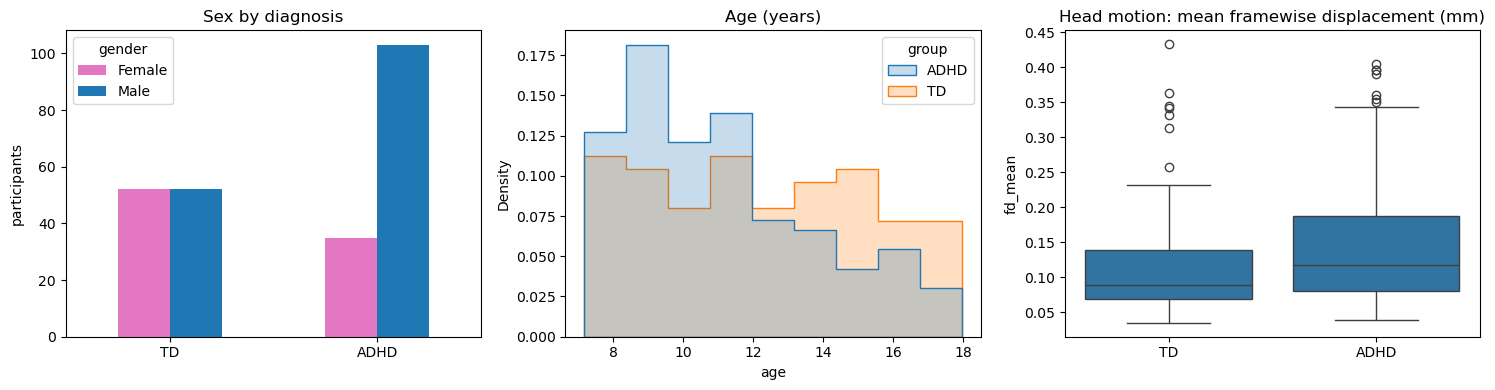

In [4]:
def describe(d):
    g = d.groupby('y')
    out = pd.DataFrame({'n': g.size(), 'male %': (g.male.mean()*100).round(1),
                        'age mean (SD)': g.age.agg(lambda a: f'{a.mean():.1f} ({a.std():.1f})'),
                        'mean FD mm (SD)': g.fd_mean.agg(lambda a: f'{a.mean():.3f} ({a.std():.3f})')})
    out.index = out.index.map({0: 'TD', 1: 'ADHD'})
    return out
display(describe(df))
print('Sex vs diagnosis   chi2 p = %.2g' % stats.chi2_contingency(pd.crosstab(df.male, df.y))[1])
print('Age  ADHD vs TD    t-test p = %.2g' % stats.ttest_ind(df.age[df.y==1], df.age[df.y==0]).pvalue)
print('Motion ADHD vs TD  Mann-Whitney p = %.2g' % stats.mannwhitneyu(df.fd_mean[df.y==1], df.fd_mean[df.y==0]).pvalue)

grp = df.y.map({0: 'TD', 1: 'ADHD'}).rename('group')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pd.crosstab(grp, df.gender).loc[['TD', 'ADHD']].plot.bar(ax=axes[0], rot=0, color=['tab:pink', 'tab:blue'])
axes[0].set_title('Sex by diagnosis'); axes[0].set_xlabel(''); axes[0].set_ylabel('participants')
sns.histplot(x=df.age, hue=grp, element='step', stat='density', common_norm=False, ax=axes[1]); axes[1].set_title('Age (years)')
sns.boxplot(x=grp, y=df.fd_mean, order=['TD', 'ADHD'], ax=axes[2]); axes[2].set_title('Head motion: mean framewise displacement (mm)'); axes[2].set_xlabel('')
plt.tight_layout(); plt.savefig('figures/demographics.png', dpi=120, bbox_inches='tight'); plt.show()

**Sex is strongly confounded with diagnosis** in this sample: most ADHD participants are boys and most girls are typically developing. Any imaging model therefore has to be compared against a sex-only rule. It also has to be checked within each sex, to see whether it just picks up sex-related signal.

## 2. fMRI preprocessing and quality control

The previous notebook used the **raw** BOLD scans (`RawDataBIDS`). Without registration, a voxel index refers to a different anatomical location in every child, and raw temporal variability is dominated by head motion and scanner drift. The per-subject maps used here are produced by `preprocess.py` (included with this notebook) as follows:

| Step | Tool | Purpose |
|---|---|---|
| 1. Head-motion correction, susceptibility-distortion correction, co-registration to T1, **normalisation to MNI152NLin2009cAsym (2 mm)** | fMRIPrep (ADHD-200 public derivatives) | Voxels correspond to the same anatomy across subjects |
| 2. Discard the first 4 volumes (8 s) | numpy | Remove the T1 equilibration transient |
| 3. Down-sample 2 mm to 4 mm (2×2×2 block average) | numpy | Mild smoothing and fewer features (23k instead of ~190k voxels) |
| 4. Convert to % signal change per voxel | numpy | Removes arbitrary scanner intensity scaling between subjects |
| 5. Linear detrend, band-pass 0.01–0.1 Hz | `nilearn.signal.clean` | Remove drift and high-frequency noise |
| 6. Nuisance regression: mean white-matter signal + 5 tCompCor components | `nilearn.signal.clean` | Remove residual motion and physiological noise |
| 7. Per-voxel temporal SD and range of the cleaned signal | numpy | Features |
| 8. Motion QC: exclude mean framewise displacement > 0.5 mm. Mean FD is also a covariate in every analysis | MRIQC metrics | Limit motion confounding |

fMRIPrep's confound tables (the 6 realignment parameters) are not part of the public release, so these were not regressed directly. Motion is controlled through CompCor, exclusion and the FD covariate.

In [5]:
maps = {s: np.load(os.path.join(DERIV, 'maps', f'{s}.npz')) for s in df['sub']}
first = maps[df['sub'][0]]
affine, shape = first['affine'], first['mask'].shape
check('all subject maps are on one grid (identical array shape and affine)',
      all(maps[s]['mask'].shape == shape and np.allclose(maps[s]['affine'], affine) for s in df['sub']))
M = np.stack([maps[s]['mask'] for s in df['sub']])      # each subject's own brain mask
# Storage grid only: voxels inside AT LEAST ONE subject's mask. It does not decide which voxels are analysed.
# Which voxels are analysed is decided from training subjects alone (Section 3 and the FoldCoverage step in Section 5).
grid = M.any(0)
Mg = M[:, grid]
def load_feature(key):
    X = np.stack([maps[s][key][grid] for s in df['sub']]).astype(np.float64)
    X[~Mg] = np.nan                                     # outside a subject's own mask the value is missing, not zero
    return X
X_sd, X_rg = load_feature('sd'), load_feature('range')
n_grid = int(grid.sum())
COV = ['male', 'age', 'fd_mean']
C = df[COV].to_numpy(float)
y = df.y.to_numpy()
print('subjects:', len(df), '| storage grid (voxels inside at least one mask):', n_grid,
      '| voxels inside every analysed subject\'s mask (not used for analysis):', int(Mg.all(0).sum()),
      '| volumes per scan:', sorted(df.n_vols.unique()))

def to_img(values):
    # values are given on the storage grid; missing values are shown as 0
    vol = np.zeros(shape, np.float32); vol[grid] = np.nan_to_num(values)
    return nib.Nifti1Image(vol, affine)
bg = datasets.load_mni152_template(resolution=2)
check('all subjects have the same number of volumes after dummy removal (171-172)', df.n_vols.between(171, 172).all())
check('feature values are finite inside each subject\'s brain mask and missing (NaN) outside it',
      np.isfinite(X_sd[Mg]).all() and np.isfinite(X_rg[Mg]).all() and np.isnan(X_sd[~Mg]).all() and np.isnan(X_rg[~Mg]).all())
check('covariates are valid (diagnosis and sex coded 0/1, age 5-22 years, mean FD finite and positive)',
      set(np.unique(y)) <= {0, 1} and set(np.unique(C[:, 0])) <= {0.0, 1.0} and np.isfinite(C).all()
      and ((C[:, 1] >= 5) & (C[:, 1] <= 22)).all() and (C[:, 2] > 0).all())

PASSED: all subject maps are on one grid (identical array shape and affine)


subjects: 242 | storage grid (voxels inside at least one mask): 41653 | voxels inside every analysed subject's mask (not used for analysis): 23444 | volumes per scan: [171.0, 172.0]


PASSED: all subjects have the same number of volumes after dummy removal (171-172)
PASSED: feature values are finite inside each subject's brain mask and missing (NaN) outside it
PASSED: covariates are valid (diagnosis and sex coded 0/1, age 5-22 years, mean FD finite and positive)


### 2.1 What this notebook can and cannot verify about preprocessing

This notebook does not preprocess the scans. It loads one feature file per subject (`derivatives/maps/sub-*.npz`) written by `preprocess.py`. The cell below records where those files come from and checks what can be checked from them:

* **Provenance:** SHA-256 of `preprocess.py`, number of feature files, and agreement between the QC record embedded in each file and `derivatives/qc.csv`.
* **Spatial grid:** every file has the same array shape and affine (checked above).
* **Spatial alignment:** each subject's SD map is correlated with the group-mean SD map. A scan that was not in MNI space would not correlate with the others.

**Not verifiable here:** the band-pass filter and the nuisance regression act on the time series, which are not stored (only SD and range are kept). They can be verified only by reading `preprocess.py` and by re-running it. `verify_preprocessing.py` re-downloads and re-processes subjects and compares the result with the stored files; if its output (`derivatives/verification.json`) is present, it is shown below.

In [6]:
import hashlib, json as _json
sha = hashlib.sha256(open('preprocess.py', 'rb').read()).hexdigest()
n_files = len(glob.glob(os.path.join(DERIV, 'maps', '*.npz')))
print(f'preprocess.py SHA-256: {sha}')
print(f'feature files in {DERIV}/maps: {n_files} | rows in qc.csv: {len(qc)} | subjects analysed: {len(df)}')
emb = pd.DataFrame([_json.loads(str(maps[s]['qc'])) for s in df['sub']])
check('each analysed subject has one feature file whose embedded QC record (subject ID, volumes, mean FD) matches qc.csv',
      (emb['sub'].to_numpy() == df['sub'].to_numpy()).all() and (emb.n_vols.to_numpy() == df.n_vols.to_numpy()).all()
      and np.allclose(emb.fd_mean.to_numpy(float), df.fd_mean.to_numpy(float)))
mean_map = np.nanmean(X_sd, 0)
r_align = np.array([np.corrcoef(X_sd[i, Mg[i]], mean_map[Mg[i]])[0, 1] for i in range(len(df))])
print(f'spatial correlation of each subject\'s SD map with the group-mean SD map: min {r_align.min():.2f}, '
      f'5th percentile {np.quantile(r_align, .05):.2f}, median {np.median(r_align):.2f}')
check('every subject\'s SD map correlates with the group-mean map (r > 0.5), as expected for spatially aligned data', (r_align > 0.5).all())
vpath = os.path.join(DERIV, 'verification.json')
if os.path.exists(vpath):
    ver = _json.load(open(vpath))
    print(f"independent re-run of preprocess.py ({ver['date']}): {len(ver['subjects'])} subject(s) re-downloaded and re-processed")
    display(pd.DataFrame(ver['subjects']))
else:
    ver = None
    print('no verification.json found: preprocessing has not been independently re-run for this copy')

preprocess.py SHA-256: 7e4b53cd08daed431dffc323d0bee8664af6cd44db0ef1105116ba809b400510
feature files in derivatives/maps: 255 | rows in qc.csv: 255 | subjects analysed: 242
PASSED: each analysed subject has one feature file whose embedded QC record (subject ID, volumes, mean FD) matches qc.csv
spatial correlation of each subject's SD map with the group-mean SD map: min 0.63, 5th percentile 0.69, median 0.77
PASSED: every subject's SD map correlates with the group-mean map (r > 0.5), as expected for spatially aligned data
independent re-run of preprocess.py (2026-11-12): 3 subject(s) re-downloaded and re-processed


,subject,"same grid (shape, affine)",same brain mask,max |difference| SD (% signal),max |difference| range (% signal),correlation of SD maps
0,sub-0010001,True,True,0.0,0.0,1.0
1,sub-0010052,True,True,0.0,0.0,1.0
2,sub-0010116,True,True,0.0,0.0,1.0


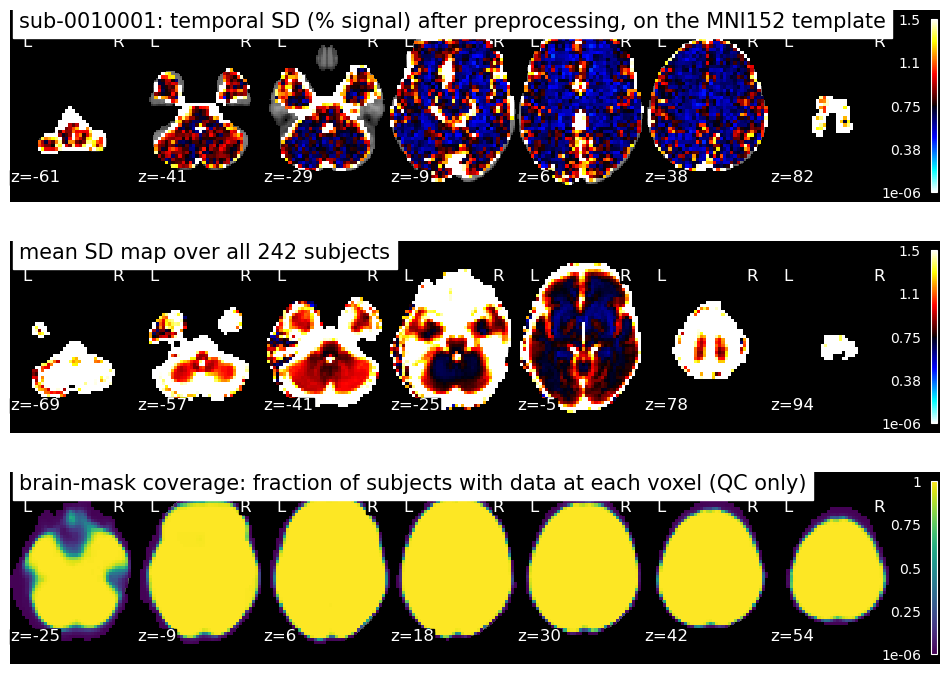

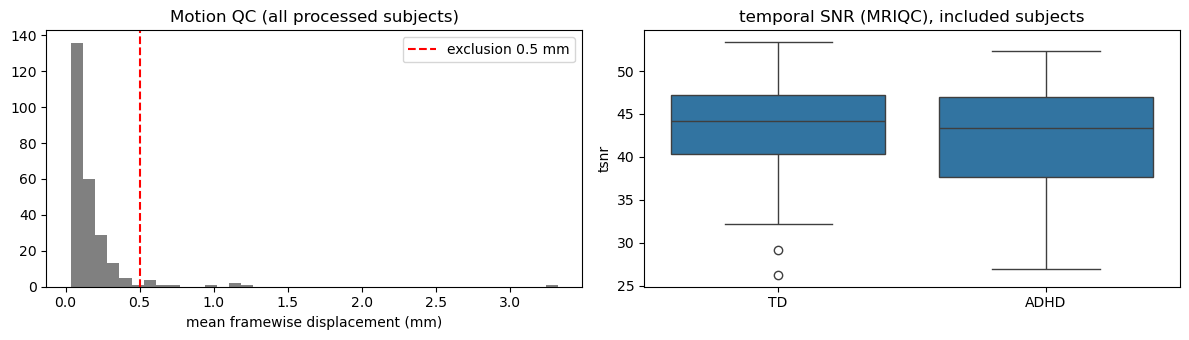

In [7]:
# Registration check: subject maps are in MNI space, so they line up with the MNI template and with each other
example = df['sub'][0]
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5))
plotting.plot_stat_map(to_img(X_sd[0]), bg_img=bg, display_mode='z', cut_coords=7, axes=axes[0], vmax=1.5,
                       title=f'{example}: temporal SD (% signal) after preprocessing, on the MNI152 template')
plotting.plot_stat_map(to_img(np.nanmean(X_sd, 0)), bg_img=bg, display_mode='z', cut_coords=7, axes=axes[1], vmax=1.5,
                       title=f'mean SD map over all {len(df)} subjects')
plotting.plot_stat_map(to_img(Mg.mean(0)), bg_img=bg, display_mode='z', cut_coords=7, axes=axes[2], vmax=1.0, cmap='viridis',
                       title='brain-mask coverage: fraction of subjects with data at each voxel (QC only)')
plt.savefig('figures/registration_check.png', dpi=120, bbox_inches='tight'); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
qc_all = p.merge(qc, on='sub')
axes[0].hist(qc_all.fd_mean, bins=40, color='gray'); axes[0].axvline(FD_MAX, color='r', ls='--', label=f'exclusion {FD_MAX} mm')
axes[0].set_xlabel('mean framewise displacement (mm)'); axes[0].set_title('Motion QC (all processed subjects)'); axes[0].legend()
sns.boxplot(x=grp, y=df.tsnr, order=['TD', 'ADHD'], ax=axes[1]); axes[1].set_title('temporal SNR (MRIQC), included subjects'); axes[1].set_xlabel('')
plt.tight_layout(); plt.savefig('figures/qc.png', dpi=120, bbox_inches='tight'); plt.show()

## 3. Train / test split

The split is stratified by **diagnosis × sex**, so both sets have the same sex mix. The test set (20%) is not used again until Section 7.

In [8]:
strata = df.y.astype(str) + '_' + df.male.astype(int).astype(str)
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, stratify=strata, random_state=SEED)
tr = df.iloc[idx_tr]; te = df.iloc[idx_te]
print(f'train n={len(idx_tr)} (ADHD {y[idx_tr].sum()}, TD {(1-y[idx_tr]).sum()})   '
      f'test n={len(idx_te)} (ADHD {y[idx_te].sum()}, TD {(1-y[idx_te]).sum()})')
display(pd.concat({'train': describe(tr), 'test': describe(te)}))

check('no subject ID appears in both the training list and the test list', set(tr['sub']).isdisjoint(te['sub']))
check('training list + test list = all analysed subjects', len(set(tr['sub']) | set(te['sub'])) == len(df) == len(idx_tr) + len(idx_te))

# Analysis mask for the training-set analyses (Section 4): voxels inside the brain mask of EVERY TRAINING subject.
# Test subjects are not consulted. The classifiers derive their own mask inside each fold (FoldCoverage, Section 5).
cov_tr = Mg[idx_tr].all(0)
n_vox = int(cov_tr.sum())
n_missing_te = (~Mg[idx_te][:, cov_tr]).sum(1)
print(f'analysis mask from the {len(idx_tr)} training subjects: {n_vox} voxels')
print(f'test subjects with at least one of these voxels missing: {(n_missing_te > 0).sum()} of {len(idx_te)} '
      f'(at most {n_missing_te.max()} voxels each); missing values are filled with the training mean of that voxel')
def on_grid(v):
    out = np.zeros(n_grid); out[cov_tr] = v
    return out
check('the training-set analysis mask is computed from training rows only and every training subject has data in all of it',
      np.isfinite(X_sd[idx_tr][:, cov_tr]).all() and np.isfinite(X_rg[idx_tr][:, cov_tr]).all())
tr[['sub', 'dx', 'gender', 'age', 'fd_mean']].to_csv('splits/train_subjects.csv', index=False)
te[['sub', 'dx', 'gender', 'age', 'fd_mean']].to_csv('splits/test_subjects.csv', index=False)
print('subject lists saved to splits/train_subjects.csv and splits/test_subjects.csv')

train n=193 (ADHD 110, TD 83)   test n=49 (ADHD 28, TD 21)


n  male % age mean (SD) mean FD mm (SD)
      y                                              
train TD     83    50.6    12.3 (3.1)   0.114 (0.079)
      ADHD  110    74.5    11.0 (2.7)   0.146 (0.089)
test  TD     21    47.6    12.4 (3.3)   0.124 (0.076)
      ADHD   28    75.0    11.3 (2.7)   0.129 (0.072)

PASSED: no subject ID appears in both the training list and the test list
PASSED: training list + test list = all analysed subjects
analysis mask from the 193 training subjects: 23576 voxels
test subjects with at least one of these voxels missing: 34 of 49 (at most 25 voxels each); missing values are filled with the training mean of that voxel
PASSED: the training-set analysis mask is computed from training rows only and every training subject has data in all of it
subject lists saved to splits/train_subjects.csv and splits/test_subjects.csv


## 4. Inference: which voxels differ between ADHD and TD? (training set only)

For each voxel we fit the ordinary least-squares model `feature ~ 1 + ADHD + sex + age + mean FD` and test the ADHD coefficient (two-sided t-test). P-values are corrected for all voxels of the training-set analysis mask (Section 3) with the Benjamini–Hochberg FDR method (q < 0.05). A large difference between group means is not on its own evidence of an effect.

In [9]:
def voxel_glm(Y, design, col=1):
    # OLS for all voxels at once; returns t and two-sided p for column `col`
    beta, _, _, _ = np.linalg.lstsq(design, Y, rcond=None)
    resid = Y - design @ beta
    dof = design.shape[0] - design.shape[1]
    sigma2 = (resid ** 2).sum(0) / dof
    se = np.sqrt(sigma2 * np.linalg.inv(design.T @ design)[col, col])
    t = beta[col] / se
    return t, 2 * stats.t.sf(np.abs(t), dof)

def fdr_bh(pvals, q=0.05):
    p_sorted = np.sort(pvals); m = len(pvals)
    below = p_sorted <= q * np.arange(1, m + 1) / m
    return pvals <= (p_sorted[below].max() if below.any() else -1)

design = np.column_stack([np.ones(len(idx_tr)), y[idx_tr], C[idx_tr]])
glm = {}
for name, X in [('SD', X_sd), ('Range', X_rg)]:
    t, pv = voxel_glm(X[idx_tr][:, cov_tr], design)
    glm[name] = (t, pv)
    print(f'{name:5s}: voxels p<0.001 uncorrected = {np.sum(pv < 0.001):5d} | '
          f'FDR q<0.05 = {fdr_bh(pv).sum():4d} of {n_vox} | min p = {pv.min():.2g}')

SD   : voxels p<0.001 uncorrected =    29 | FDR q<0.05 =    0 of 23576 | min p = 3.2e-06


Range: voxels p<0.001 uncorrected =    27 | FDR q<0.05 =    0 of 23576 | min p = 1.9e-05


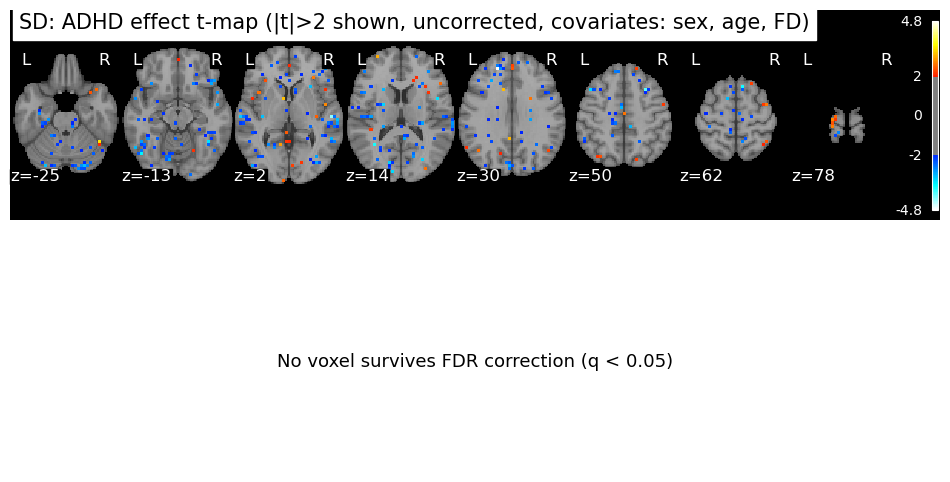

In [10]:
t_sd, p_sd = glm['SD']
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
plotting.plot_stat_map(to_img(on_grid(t_sd)), bg_img=bg, display_mode='z', cut_coords=8, threshold=2.0, axes=axes[0],
                       title='SD: ADHD effect t-map (|t|>2 shown, uncorrected, covariates: sex, age, FD)')
sig = fdr_bh(p_sd)
if sig.any():
    plotting.plot_stat_map(to_img(on_grid(t_sd * sig)), bg_img=bg, display_mode='z', cut_coords=8, axes=axes[1],
                           title='SD: voxels surviving FDR q<0.05')
else:
    axes[1].axis('off'); axes[1].text(0.5, 0.5, 'No voxel survives FDR correction (q < 0.05)', ha='center', fontsize=13)
plt.savefig('figures/glm_tmap_sd.png', dpi=120, bbox_inches='tight'); plt.show()

### 4.2 The original voxel-selection procedure (descriptive only)

The original approach took the absolute difference between the ADHD and TD group-mean SD maps and kept the voxels above Otsu's threshold. Below, that procedure is recomputed on the training set. The table then shows how many of the selected voxels have even an uncorrected effect once sex, age and motion are accounted for.

K-means on the voxel coordinates groups the selected voxels into spatially compact blobs. These clusters are **only a visual summary**. They are not functional brain regions and say nothing about connectivity, which would need for example time-series correlations between regions and an atlas-based or data-driven parcellation.

Otsu threshold on |mean ADHD - mean TD| (SD, % signal): 0.0808 -> 1653 voxels (7.0% of brain voxels, ~93% of voxels lie below the threshold)
of those, uncorrected p<0.05 in the covariate-adjusted GLM: 269; FDR-significant: 0


connected components among selected voxels: 389


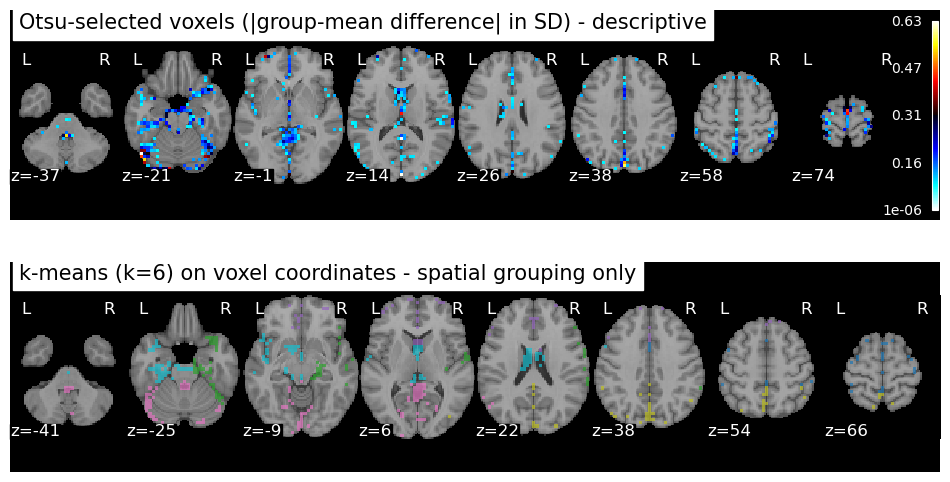

In [11]:
def otsu_threshold(values, bins=128):
    # Otsu's method in numpy (the same thresholding rule as the original analysis)
    hist, edges = np.histogram(values, bins=bins)
    mids = (edges[:-1] + edges[1:]) / 2
    w1 = np.cumsum(hist); w2 = np.cumsum(hist[::-1])[::-1]
    m1 = np.cumsum(hist * mids) / np.maximum(w1, 1)
    m2 = (np.cumsum((hist * mids)[::-1]) / np.maximum(w2[::-1], 1))[::-1]
    var12 = w1[:-1] * w2[1:] * (m1[:-1] - m2[1:]) ** 2
    return mids[:-1][np.argmax(var12)]

ytr = y[idx_tr]
Xtr_sd = X_sd[idx_tr][:, cov_tr]
diff = np.abs(Xtr_sd[ytr == 1].mean(0) - Xtr_sd[ytr == 0].mean(0))
thr = otsu_threshold(diff); sel = diff > thr
print(f'Otsu threshold on |mean ADHD - mean TD| (SD, % signal): {thr:.4f} -> {sel.sum()} voxels '
      f'({100*sel.mean():.1f}% of brain voxels, ~{np.mean(diff <= thr)*100:.0f}% of voxels lie below the threshold)')
print(f'of those, uncorrected p<0.05 in the covariate-adjusted GLM: {np.sum(p_sd[sel] < 0.05)}; '
      f'FDR-significant: {np.sum(fdr_bh(p_sd)[sel])}')

coords = np.argwhere(to_img(on_grid(sel.astype(float))).get_fdata() > 0)
km = KMeans(n_clusters=6, random_state=0, n_init=10).fit(coords)
km_vol = np.zeros(shape, np.float32); km_vol[tuple(coords.T)] = km.labels_ + 1
_, n_cc = ndimage.label(to_img(on_grid(sel.astype(float))).get_fdata() > 0)
print('connected components among selected voxels:', n_cc)
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
plotting.plot_stat_map(to_img(on_grid(diff * sel)), bg_img=bg, display_mode='z', cut_coords=8, axes=axes[0],
                       title='Otsu-selected voxels (|group-mean difference| in SD) - descriptive')
plotting.plot_roi(nib.Nifti1Image(km_vol, affine), bg_img=bg, display_mode='z', cut_coords=8, axes=axes[1],
                  cmap='tab10', title='k-means (k=6) on voxel coordinates - spatial grouping only')
plt.savefig('figures/otsu_kmeans.png', dpi=120, bbox_inches='tight'); plt.show()

## 5. Candidate models and baselines

All candidates take the same input: `[sex, age, mean FD | SD voxels | range voxels]`. Each pipeline uses only the columns it needs. Every data-dependent step is learned from the training fold alone: the brain mask (voxels covered by every training-fold subject), Otsu voxel selection, scaling, PCA and the classifier.

* **Baselines:** majority class, the reviewer's sex rule (boy → ADHD), logistic regression on sex + age, on motion alone, and on sex + age + motion.
* **Imaging:** {SD, range} × {Otsu voxels, Otsu voxels + PCA 95%} × {logistic regression, linear SVM, random forest, XGBoost}.
* **Imaging + covariates:** sex, age and motion added to the PCA-reduced imaging features.

In [12]:
COLS = {'cov': np.arange(3), 'sd': 3 + np.arange(n_grid), 'range': 3 + n_grid + np.arange(n_grid)}
Z = np.hstack([C, X_sd, X_rg])

class FoldCoverage(BaseEstimator, TransformerMixin):
    # mask learned from the training fold alone: keep voxels that lie inside the brain mask of every training-fold subject.
    # A held-out subject with no data at a kept voxel gets the training-fold mean of that voxel.
    def fit(self, X, y=None):
        self.keep_ = ~np.isnan(X).any(0)
        self.mean_ = X[:, self.keep_].mean(0)
        return self
    def transform(self, X):
        Xk = X[:, self.keep_].copy()
        miss = np.isnan(Xk)
        if miss.any():
            Xk[miss] = np.broadcast_to(self.mean_, Xk.shape)[miss]
        return Xk

class OtsuVoxelSelector(BaseEstimator, TransformerMixin):
    # original selection rule, refit on each training fold: keep voxels whose |mean ADHD - mean TD| > Otsu threshold
    def fit(self, X, y):
        d = np.abs(X[y == 1].mean(0) - X[y == 0].mean(0))
        self.support_ = d > otsu_threshold(d)
        return self
    def transform(self, X):
        return X[:, self.support_]

class SexRule(BaseEstimator, ClassifierMixin):
    # reviewer's baseline: predict ADHD for boys, TD for girls (column 0 of Z = male)
    def fit(self, X, y):
        self.classes_ = np.array([0, 1]); return self
    def predict(self, X):
        return (X[:, 0] == 1).astype(int)
    def predict_proba(self, X):
        p = self.predict(X).astype(float); return np.column_stack([1 - p, p])

class BalancedXGB(BaseEstimator, ClassifierMixin):
    # XGBoost with scale_pos_weight = n_negative / n_positive computed from the training fold
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        self.model_ = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8,
                                    colsample_bytree=0.5, eval_metric='logloss', random_state=SEED, n_jobs=1,
                                    scale_pos_weight=(y == 0).sum() / max((y == 1).sum(), 1)).fit(X, y)
        return self
    def predict(self, X): return self.model_.predict(X)
    def predict_proba(self, X): return self.model_.predict_proba(X)

def cols(name):
    return ColumnTransformer([('pick', 'passthrough', COLS[name])])

def classifier(name):
    return {'LogReg': LogisticRegression(C=0.01, max_iter=5000, class_weight='balanced'),
            'SVM-linear': SVC(kernel='linear', C=0.001, probability=True, class_weight='balanced', random_state=SEED),
            'RandomForest': RandomForestClassifier(n_estimators=500, max_features='sqrt', class_weight='balanced',
                                                   min_samples_leaf=3, random_state=SEED, n_jobs=1),
            'XGBoost': BalancedXGB(),
            }[name]

def imaging(feat, pca):
    steps = [('pick', cols(feat)), ('cover', FoldCoverage()), ('otsu', OtsuVoxelSelector()), ('scale', StandardScaler())]
    return steps + ([('pca', PCA(n_components=0.95, random_state=SEED))] if pca else [])

candidates = {
    'Baseline: majority class': Pipeline([('pick', cols('cov')), ('clf', DummyClassifier(strategy='most_frequent'))]),
    'Baseline: sex rule (boy=ADHD)': Pipeline([('pick', cols('cov')), ('clf', SexRule())]),
    'Baseline: LogReg sex+age': Pipeline([('pick', ColumnTransformer([('p', 'passthrough', [0, 1])])),
                                          ('scale', StandardScaler()), ('clf', LogisticRegression(class_weight='balanced'))]),
    'Baseline: LogReg motion': Pipeline([('pick', ColumnTransformer([('p', 'passthrough', [2])])),
                                         ('scale', StandardScaler()), ('clf', LogisticRegression(class_weight='balanced'))]),
    'Baseline: LogReg sex+age+motion': Pipeline([('pick', cols('cov')), ('scale', StandardScaler()),
                                                 ('clf', LogisticRegression(class_weight='balanced'))]),
}
for feat in ['sd', 'range']:
    for pca in [False, True]:
        for clf in ['LogReg', 'SVM-linear', 'RandomForest', 'XGBoost']:
            candidates[f'Imaging {feat.upper()}{" + PCA" if pca else ""}: {clf}'] = Pipeline(imaging(feat, pca) + [('clf', classifier(clf))])
    for clf in ['LogReg', 'SVM-linear', 'RandomForest', 'XGBoost']:
        combo = ColumnTransformer([('cov', StandardScaler(), COLS['cov']),
                                   ('img', Pipeline(imaging(feat, True)[1:]), COLS[feat])])
        candidates[f'Imaging {feat.upper()} + PCA + sex/age/motion: {clf}'] = Pipeline([('feat', combo), ('clf', classifier(clf))])
print(len(candidates), 'candidate pipelines')

29 candidate pipelines


Regularisation strengths (C = 0.01 for logistic regression, 0.001 for the linear SVM) are fixed in advance rather than tuned. With about 190 training subjects and thousands of voxels, weak regularisation overfits: the original SVM used C = 1. Because ADHD outnumbers TD, all learned models use balanced class weights, and model selection uses **balanced accuracy**. Plain accuracy would reward predicting "ADHD" for everyone.

## 6. Model selection: repeated stratified 5-fold CV on the training set

### Metric definitions (ADHD = positive class)

| Metric | Formula | Meaning here |
|---|---|---|
| Accuracy | (TP + TN) / N | fraction of children classified correctly |
| Balanced accuracy | (sensitivity + specificity) / 2 | accuracy that is not inflated by the ADHD majority (57%) |
| Sensitivity (recall) | TP / (TP + FN) | fraction of ADHD children detected |
| **Specificity** | TN / (TN + FP) | fraction of TD children correctly called TD |
| **Precision** (PPV) | TP / (TP + FP) | when the model says ADHD, how often it is right |
| **F1** | 2 · precision · sensitivity / (precision + sensitivity) | harmonic mean of precision and sensitivity |
| ROC AUC | area under the ROC curve | threshold-free ranking quality |

Every metric is reported for every model, both in CV (mean ± SD over 25 folds) and on the test set (with 95% CIs).

In [13]:
def specificity(y_true, y_pred): return recall_score(y_true, y_pred, pos_label=0)
SCORING = {'balanced_accuracy': 'balanced_accuracy', 'accuracy': 'accuracy', 'roc_auc': 'roc_auc',
           'sensitivity': 'recall', 'specificity': make_scorer(specificity), 'precision': make_scorer(precision_score, zero_division=0),
           'f1': 'f1'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
Ztr, ytr = Z[idx_tr], y[idx_tr]

t0 = time.time(); rows = []; fold_scores = {}
for name, pipe in candidates.items():
    r = cross_validate(pipe, Ztr, ytr, cv=cv, scoring=SCORING, n_jobs=N_JOBS, error_score='raise')
    fold_scores[name] = r
    rows.append({'model': name, **{m: r[f'test_{m}'].mean() for m in SCORING},
                 **{f'{m}_sd': r[f'test_{m}'].std() for m in SCORING}})
cv_table = pd.DataFrame(rows).set_index('model').sort_values('balanced_accuracy', ascending=False)
cv_table['bal_acc_sd'] = cv_table['balanced_accuracy_sd']
print(f'CV done in {time.time()-t0:.0f} s')
cv_table.to_csv('cv_results_training.csv')
METRIC_ORDER = ['balanced_accuracy', 'accuracy', 'sensitivity', 'specificity', 'precision', 'f1', 'roc_auc']
cv_pretty = pd.DataFrame({m: [f'{a:.3f} ± {b:.3f}' for a, b in zip(cv_table[m], cv_table[f'{m}_sd'])] for m in METRIC_ORDER},
                         index=cv_table.index)
print('Training-set CV (5-fold x 5 repeats), mean ± SD over the 25 folds; sorted by balanced accuracy')
display(cv_pretty)

CV done in 124 s
Training-set CV (5-fold x 5 repeats), mean ± SD over the 25 folds; sorted by balanced accuracy


,balanced_accuracy,accuracy,sensitivity,specificity,precision,f1,roc_auc
model,,,,,,,
Imaging SD + PCA + sex/age/motion: LogReg,0.633 ± 0.057,0.651 ± 0.057,0.756 ± 0.084,0.510 ± 0.090,0.673 ± 0.044,0.710 ± 0.052,0.683 ± 0.058
Imaging SD + PCA: LogReg,0.632 ± 0.056,0.650 ± 0.055,0.758 ± 0.085,0.506 ± 0.091,0.671 ± 0.043,0.710 ± 0.051,0.681 ± 0.057
Imaging SD + PCA + sex/age/motion: SVM-linear,0.628 ± 0.051,0.642 ± 0.052,0.731 ± 0.104,0.525 ± 0.100,0.673 ± 0.042,0.697 ± 0.057,0.689 ± 0.059
Imaging SD + PCA: SVM-linear,0.628 ± 0.050,0.642 ± 0.051,0.733 ± 0.104,0.522 ± 0.101,0.672 ± 0.041,0.697 ± 0.056,0.687 ± 0.058
Imaging SD: LogReg,0.626 ± 0.055,0.642 ± 0.056,0.745 ± 0.089,0.506 ± 0.085,0.667 ± 0.044,0.702 ± 0.055,0.673 ± 0.058
Imaging RANGE: SVM-linear,0.624 ± 0.055,0.635 ± 0.056,0.704 ± 0.100,0.545 ± 0.111,0.675 ± 0.053,0.685 ± 0.057,0.660 ± 0.063
Imaging RANGE: LogReg,0.624 ± 0.051,0.637 ± 0.053,0.720 ± 0.091,0.528 ± 0.087,0.670 ± 0.045,0.692 ± 0.055,0.664 ± 0.062
Imaging SD: SVM-linear,0.621 ± 0.047,0.635 ± 0.048,0.722 ± 0.101,0.520 ± 0.100,0.668 ± 0.039,0.690 ± 0.054,0.671 ± 0.060
Baseline: sex rule (boy=ADHD),0.620 ± 0.080,0.638 ± 0.079,0.745 ± 0.086,0.494 ± 0.104,0.662 ± 0.064,0.700 ± 0.068,0.620 ± 0.080


Selected by CV (highest mean balanced accuracy): Imaging SD + PCA + sex/age/motion: LogReg
Best imaging-only pipeline:                      Imaging SD + PCA: LogReg


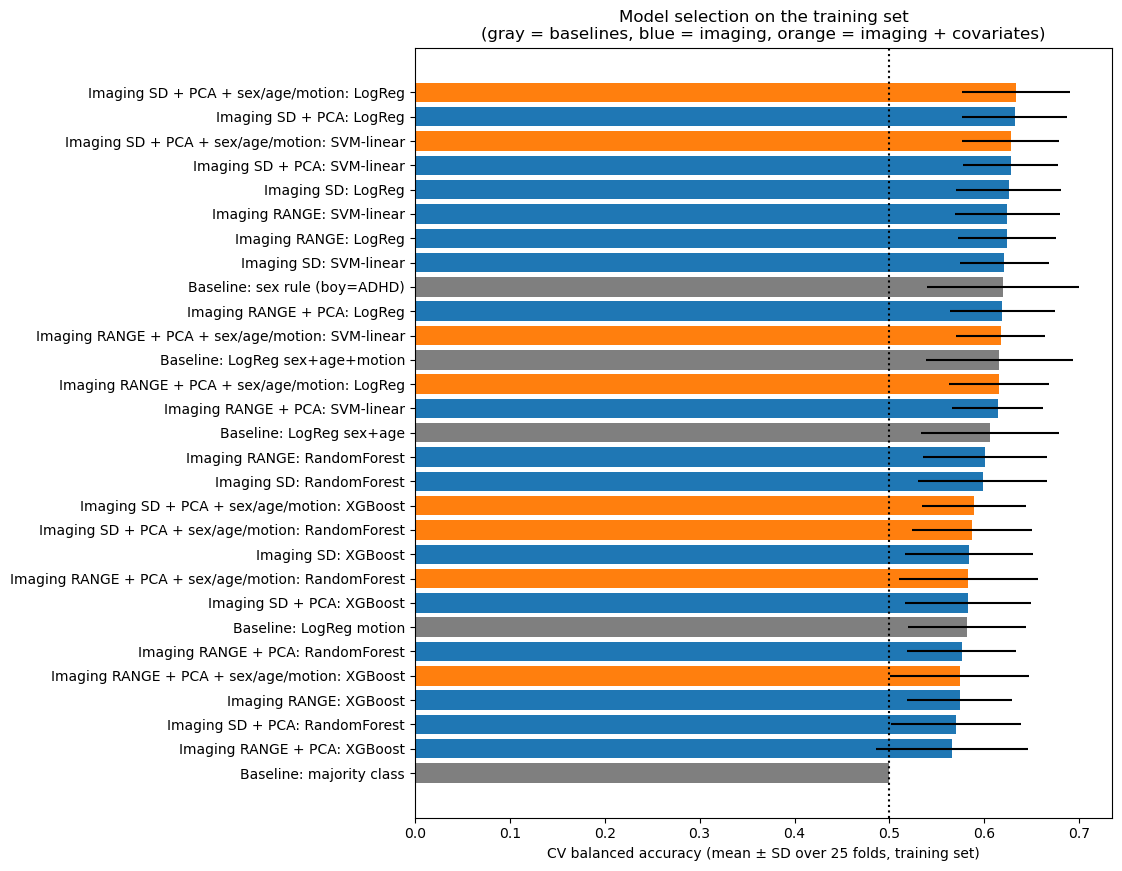

In [14]:
best_name = cv_table.index[0]
best_img_name = cv_table[cv_table.index.str.startswith('Imaging') & ~cv_table.index.str.contains('sex/age')].index[0]
print('Selected by CV (highest mean balanced accuracy):', best_name)
print('Best imaging-only pipeline:                     ', best_img_name)
fig, ax = plt.subplots(figsize=(9, 10))
order = cv_table.index[::-1]
colors = ['tab:gray' if n.startswith('Baseline') else ('tab:orange' if 'sex/age' in n else 'tab:blue') for n in order]
ax.barh(order, cv_table.loc[order, 'balanced_accuracy'], xerr=cv_table.loc[order, 'bal_acc_sd'], color=colors)
ax.axvline(0.5, color='k', ls=':'); ax.set_xlabel('CV balanced accuracy (mean ± SD over 25 folds, training set)')
ax.set_title('Model selection on the training set\n(gray = baselines, blue = imaging, orange = imaging + covariates)')
plt.savefig('figures/cv_model_selection.png', dpi=120, bbox_inches='tight'); plt.show()

### 6.1 Is the difference from the baselines more than fold-to-fold noise?

The 25 folds of a repeated 5-fold CV share training subjects, so they are not independent and an ordinary paired t-test is too optimistic. The **corrected resampled t-test** (Nadeau & Bengio, 2003) inflates the variance by the test/train size ratio to account for this. All models were scored on the same 25 folds, so the comparison is paired.

In [15]:
def corrected_resampled_t(d, test_frac=0.2):
    # Nadeau & Bengio (2003): variance of the fold differences is multiplied by (1/J + n_test/n_train) instead of 1/J
    J = len(d); v = d.var(ddof=1)
    if v == 0:
        return 0.0, 1.0
    t = d.mean() / np.sqrt((1 / J + test_frac / (1 - test_frac)) * v)
    return float(t), float(2 * stats.t.sf(abs(t), J - 1))

rows_c = []
for ref in ['Baseline: sex rule (boy=ADHD)', 'Baseline: LogReg sex+age+motion']:
    for n in dict.fromkeys([best_name, best_img_name]):
        for m in ['balanced_accuracy', 'sensitivity', 'specificity']:
            d = fold_scores[n][f'test_{m}'] - fold_scores[ref][f'test_{m}']
            t_c, p_c = corrected_resampled_t(d)
            rows_c.append({'model': n, 'compared with': ref, 'metric': m, 'mean difference': d.mean(), 'corrected t': t_c, 'p': p_c})
cv_compare = pd.DataFrame(rows_c)
print('Paired comparison on the 25 training-set CV folds (corrected resampled t-test, 24 d.f.)')
display(cv_compare.round(3))

Paired comparison on the 25 training-set CV folds (corrected resampled t-test, 24 d.f.)


,model,compared with,metric,mean difference,corrected t,p
0,Imaging SD + PCA + sex/age/motion: LogReg,Baseline: sex rule (boy=ADHD),balanced_accuracy,0.013,0.295,0.771
1,Imaging SD + PCA + sex/age/motion: LogReg,Baseline: sex rule (boy=ADHD),sensitivity,0.011,0.169,0.867
2,Imaging SD + PCA + sex/age/motion: LogReg,Baseline: sex rule (boy=ADHD),specificity,0.016,0.235,0.816
3,Imaging SD + PCA: LogReg,Baseline: sex rule (boy=ADHD),balanced_accuracy,0.012,0.272,0.788
4,Imaging SD + PCA: LogReg,Baseline: sex rule (boy=ADHD),sensitivity,0.013,0.193,0.849
5,Imaging SD + PCA: LogReg,Baseline: sex rule (boy=ADHD),specificity,0.011,0.170,0.867
6,Imaging SD + PCA + sex/age/motion: LogReg,Baseline: LogReg sex+age+motion,balanced_accuracy,0.017,0.388,0.701
7,Imaging SD + PCA + sex/age/motion: LogReg,Baseline: LogReg sex+age+motion,sensitivity,0.127,1.942,0.064
8,Imaging SD + PCA + sex/age/motion: LogReg,Baseline: LogReg sex+age+motion,specificity,-0.092,-1.634,0.115
9,Imaging SD + PCA: LogReg,Baseline: LogReg sex+age+motion,balanced_accuracy,0.016,0.360,0.722


### 6.2 Is the imaging signal more than sex? Within-sex performance (out-of-fold predictions on the training set)

If an imaging model only recovered sex, its balanced accuracy *within* boys and *within* girls would be about 0.5.

In [16]:
def within_sex(pipe, X, yy, male):
    pred = cross_val_predict(pipe, X, yy, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=N_JOBS)
    return {sex: balanced_accuracy_score(yy[male == v], pred[male == v]) for sex, v in [('boys', 1), ('girls', 0)]} | \
           {'overall': balanced_accuracy_score(yy, pred)}
ws = pd.DataFrame({n: within_sex(candidates[n], Ztr, ytr, Ztr[:, 0]) for n in
                   dict.fromkeys([best_name, best_img_name, 'Baseline: LogReg sex+age+motion'])}).T
display(ws.round(3))

,boys,girls,overall
Imaging SD + PCA + sex/age/motion: LogReg,0.515,0.633,0.589
Imaging SD + PCA: LogReg,0.515,0.633,0.589
Baseline: LogReg sex+age+motion,0.563,0.480,0.607


**Permutation tests.** Shuffling the labels freely also destroys the association between diagnosis and sex, age and motion. A significant result therefore shows that the imaging features predict the labels, *but not that they carry information beyond those confounds*: voxel variability can itself reflect sex, age or head motion. To test this, labels are additionally shuffled **within sex**, and **within sex × age-tercile × motion-tercile strata**. These shuffles keep the confound–diagnosis association intact, so a model that only recovers the confounds would score as well on the shuffled labels as on the real ones. In every test the whole pipeline (voxel selection, scaling, PCA, classifier) is refit on each permutation. The sex rule is not tested this way because it does not learn from the labels.

In [17]:
def fmt_p(p, n):
    # with n permutations the smallest attainable p-value is 1/(n+1); report it as an upper bound
    return f'<= {1/(n+1):.3f} (smallest attainable with {n} permutations)' if p <= 1/(n+1) + 1e-12 else f'= {p:.3f}'

n_pca = clone(candidates[best_img_name]).fit(Ztr, ytr).named_steps['pca'].n_components_
print(f'{best_img_name}: PCA keeps {n_pca} components (95% variance) when fit on the full training set')

N_PERM = 1000
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
age_t = pd.qcut(tr.age.to_numpy(), 3, labels=False, duplicates='drop')
fd_t = pd.qcut(tr.fd_mean.to_numpy(), 3, labels=False, duplicates='drop')
perm_designs = {'free': None,
                'within sex': Ztr[:, 0].astype(int),
                'within sex x age x motion': Ztr[:, 0].astype(int) * 100 + age_t * 10 + fd_t}
perm_res = {}
for lab, g in perm_designs.items():
    t0 = time.time()
    s_, null_, p_ = permutation_test_score(candidates[best_img_name], Ztr, ytr, groups=g, scoring='balanced_accuracy', cv=cv5,
                                           n_permutations=N_PERM, n_jobs=N_JOBS, random_state=SEED)
    perm_res[lab] = {'score': float(s_), 'p': float(p_), 'null_mean': float(null_.mean()), 'null_q95': float(np.quantile(null_, .95))}
    print(f'labels shuffled {lab:27s}: null mean {null_.mean():.3f}, null 95th pct {np.quantile(null_, .95):.3f}, '
          f'p {fmt_p(p_, N_PERM)}  ({time.time()-t0:.0f} s)')
score, p_perm = perm_res['free']['score'], perm_res['free']['p']
print(f'observed CV balanced accuracy of {best_img_name}: {score:.3f} ({N_PERM} permutations per test)')

Imaging SD + PCA: LogReg: PCA keeps 158 components (95% variance) when fit on the full training set


labels shuffled free                       : null mean 0.498, null 95th pct 0.570, p = 0.014  (414 s)


labels shuffled within sex                 : null mean 0.514, null 95th pct 0.582, p = 0.041  (394 s)


labels shuffled within sex x age x motion  : null mean 0.558, null 95th pct 0.620, p = 0.204  (378 s)
observed CV balanced accuracy of Imaging SD + PCA: LogReg: 0.589 (1000 permutations per test)


**Correcting the permutation test for model selection.** The p-value above is optimistic, because `best_img_name` was itself chosen as the best of the 16 imaging-only pipelines on the training data. The test below repeats the **entire selection step** under the null hypothesis. For each label permutation, all 16 imaging pipelines are cross-validated and the *maximum* balanced accuracy is recorded. The observed maximum is then compared with this null distribution of maxima, a standard max-statistic correction for multiple comparisons.

best of 16 imaging pipelines: CV balanced accuracy 0.612
null distribution of the maximum: mean 0.543, 95th percentile 0.601
selection-corrected permutation p = 0.020 (500 permutations, 10022 s)


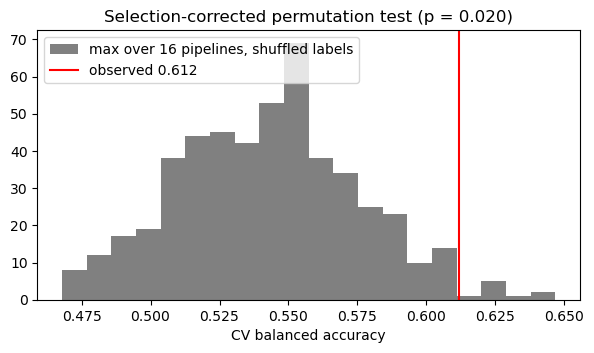

In [18]:
img_names = [n for n in candidates if n.startswith('Imaging') and 'sex/age' not in n]
cv_perm = StratifiedKFold(5, shuffle=True, random_state=SEED)
def best_imaging_cv(labels):
    return max(cross_val_score(candidates[n], Ztr, labels, cv=cv_perm, scoring='balanced_accuracy', n_jobs=N_JOBS).mean()
               for n in img_names)
N_PERM_MAX = 500
t0 = time.time()
obs_max = best_imaging_cv(ytr)
rng_perm = np.random.default_rng(SEED)
null_max = np.array([best_imaging_cv(rng_perm.permutation(ytr)) for _ in range(N_PERM_MAX)])
p_max = (1 + np.sum(null_max >= obs_max)) / (1 + N_PERM_MAX)
print(f'best of {len(img_names)} imaging pipelines: CV balanced accuracy {obs_max:.3f}')
print(f'null distribution of the maximum: mean {null_max.mean():.3f}, 95th percentile {np.quantile(null_max, .95):.3f}')
print(f'selection-corrected permutation p {fmt_p(p_max, N_PERM_MAX)} ({N_PERM_MAX} permutations, {time.time()-t0:.0f} s)')
plt.figure(figsize=(7, 3.5)); plt.hist(null_max, bins=20, color='gray', label='max over 16 pipelines, shuffled labels')
plt.axvline(obs_max, color='r', label=f'observed {obs_max:.3f}'); plt.xlabel('CV balanced accuracy'); plt.legend()
plt.title(f'Selection-corrected permutation test (p = {p_max:.3f})'); plt.savefig('figures/permutation_max.png', dpi=120, bbox_inches='tight'); plt.show()

## 7. Final evaluation on the untouched test set

Only the CV-selected model, the best imaging-only model and the baselines are evaluated here. The 95% CIs come from 2,000 bootstrap resamples of the test subjects. The paired bootstrap compares each model with the sex rule on the same resampled subjects.

In [19]:
def counts(yt, pred):
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    return tp, fn, tn, fp

def metrics(yt, pred, prob):
    # every metric computed explicitly from the confusion counts (ADHD = positive)
    tp, fn, tn, fp = counts(yt, pred)
    sens = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    prec = tp / (tp + fp) if tp + fp else 0.0
    return {'accuracy': (tp + tn) / len(yt), 'balanced_accuracy': (sens + spec) / 2, 'sensitivity': sens,
            'specificity': spec, 'precision': prec, 'f1': 2 * prec * sens / (prec + sens) if prec + sens else 0.0,
            'roc_auc': roc_auc_score(yt, prob) if len(np.unique(prob)) > 1 else 0.5}

# cross-check the hand-written formulas against scikit-learn on random predictions
_y, _p = np.random.default_rng(0).integers(0, 2, (2, 200)); _m = metrics(_y, _p, _p)
check('hand-computed metrics equal scikit-learn', np.allclose(
    [_m['accuracy'], _m['balanced_accuracy'], _m['sensitivity'], _m['specificity'], _m['precision'], _m['f1']],
    [accuracy_score(_y, _p), balanced_accuracy_score(_y, _p), recall_score(_y, _p), recall_score(_y, _p, pos_label=0),
     precision_score(_y, _p), f1_score(_y, _p)]))

Zte, yte = Z[idx_te], y[idx_te]
check('row indices used for fitting and model selection are disjoint from the test row indices', set(idx_tr).isdisjoint(idx_te))
final = dict.fromkeys([best_name, best_img_name, 'Baseline: sex rule (boy=ADHD)', 'Baseline: LogReg sex+age',
                       'Baseline: LogReg sex+age+motion', 'Baseline: majority class'])
preds = {}
for n in final:
    m = clone(candidates[n]).fit(Ztr, ytr)
    preds[n] = (m.predict(Zte), m.predict_proba(Zte)[:, 1])

rng = np.random.default_rng(SEED); B = 2000
boot_idx = [rng.integers(0, len(yte), len(yte)) for _ in range(B)]
boot_idx = [b for b in boot_idx if len(np.unique(yte[b])) == 2]
rows = []
for n, (pred, prob) in preds.items():
    point = metrics(yte, pred, prob)
    boots = pd.DataFrame([metrics(yte[b], pred[b], prob[b]) for b in boot_idx])
    rows.append({'model': n, **{k: f'{v:.3f} [{boots[k].quantile(.025):.3f}, {boots[k].quantile(.975):.3f}]'
                                for k, v in point.items()}})
test_table = pd.DataFrame(rows).set_index('model')[METRIC_ORDER]
test_table.to_csv('test_results.csv')

count_table = pd.DataFrame([dict(zip(['TP', 'FN', 'TN', 'FP'], map(int, counts(yte, preds[n][0])))) for n in preds], index=list(preds))
print(f'Test set: n={len(yte)} (ADHD {yte.sum()}, TD {(1-yte).sum()})')
print('\nConfusion counts (ADHD = positive):'); display(count_table)
print('Test-set metrics, value [95% bootstrap CI, 2000 resamples]:'); display(test_table)

PASSED: hand-computed metrics equal scikit-learn


PASSED: row indices used for fitting and model selection are disjoint from the test row indices


Test set: n=49 (ADHD 28, TD 21)

Confusion counts (ADHD = positive):


,TP,FN,TN,FP
Imaging SD + PCA + sex/age/motion: LogReg,20,8,8,13
Imaging SD + PCA: LogReg,20,8,8,13
Baseline: sex rule (boy=ADHD),21,7,11,10
Baseline: LogReg sex+age,17,11,14,7
Baseline: LogReg sex+age+motion,18,10,13,8
Baseline: majority class,28,0,0,21


Test-set metrics, value [95% bootstrap CI, 2000 resamples]:


,balanced_accuracy,accuracy,sensitivity,specificity,precision,f1,roc_auc
model,,,,,,,
Imaging SD + PCA + sex/age/motion: LogReg,"0.548 [0.406, 0.677]","0.571 [0.429, 0.694]","0.714 [0.538, 0.875]","0.381 [0.174, 0.600]","0.606 [0.433, 0.767]","0.656 [0.500, 0.783]","0.609 [0.443, 0.765]"
Imaging SD + PCA: LogReg,"0.548 [0.406, 0.677]","0.571 [0.429, 0.694]","0.714 [0.538, 0.875]","0.381 [0.174, 0.600]","0.606 [0.433, 0.767]","0.656 [0.500, 0.783]","0.604 [0.433, 0.760]"
Baseline: sex rule (boy=ADHD),"0.637 [0.498, 0.768]","0.653 [0.510, 0.776]","0.750 [0.577, 0.895]","0.524 [0.304, 0.737]","0.677 [0.514, 0.833]","0.712 [0.561, 0.828]","0.637 [0.498, 0.768]"
Baseline: LogReg sex+age,"0.637 [0.503, 0.769]","0.633 [0.490, 0.755]","0.607 [0.429, 0.778]","0.667 [0.450, 0.857]","0.708 [0.520, 0.875]","0.654 [0.500, 0.786]","0.665 [0.495, 0.815]"
Baseline: LogReg sex+age+motion,"0.631 [0.492, 0.762]","0.633 [0.490, 0.755]","0.643 [0.464, 0.808]","0.619 [0.400, 0.818]","0.692 [0.500, 0.857]","0.667 [0.510, 0.800]","0.658 [0.496, 0.818]"
Baseline: majority class,"0.500 [0.500, 0.500]","0.571 [0.429, 0.714]","1.000 [1.000, 1.000]","0.000 [0.000, 0.000]","0.571 [0.429, 0.714]","0.727 [0.600, 0.833]","0.500 [0.500, 0.500]"


Imaging SD + PCA + sex/age/motion: LogReg
   balanced accuracy minus sex rule: observed -0.089  95% bootstrap CI [-0.267, +0.076]


   sensitivity       minus sex rule: observed -0.036  95% bootstrap CI [-0.227, +0.148]


   specificity       minus sex rule: observed -0.143  95% bootstrap CI [-0.417, +0.125]


Imaging SD + PCA: LogReg
   balanced accuracy minus sex rule: observed -0.089  95% bootstrap CI [-0.267, +0.076]


   sensitivity       minus sex rule: observed -0.036  95% bootstrap CI [-0.227, +0.148]


   specificity       minus sex rule: observed -0.143  95% bootstrap CI [-0.417, +0.125]


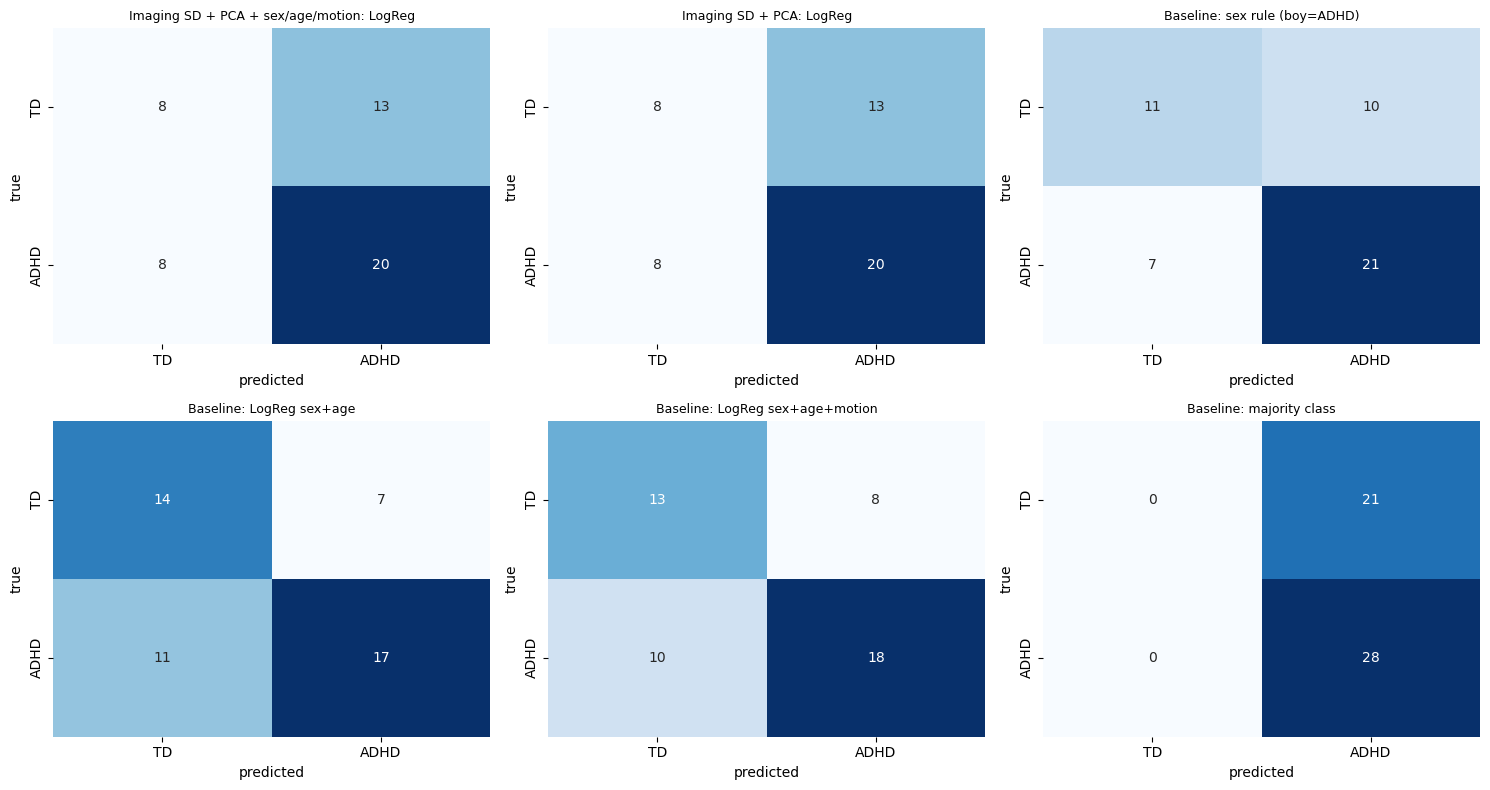

Within-sex test metrics (boys n=31, girls n=18):


,boys balanced_accuracy,boys sensitivity,boys specificity,girls balanced_accuracy,girls sensitivity,girls specificity
Imaging SD + PCA + sex/age/motion: LogReg,0.555,0.810,0.3,0.442,0.429,0.455
Imaging SD + PCA: LogReg,0.555,0.810,0.3,0.442,0.429,0.455
Baseline: sex rule (boy=ADHD),0.500,1.000,0.0,0.500,0.000,1.000
Baseline: LogReg sex+age,0.555,0.810,0.3,0.500,0.000,1.000
Baseline: LogReg sex+age+motion,0.529,0.857,0.2,0.500,0.000,1.000
Baseline: majority class,0.500,1.000,0.0,0.500,1.000,0.000


In [20]:
sex_pred = preds['Baseline: sex rule (boy=ADHD)'][0]
paired_diffs = {}     # point estimate = difference observed on the test set; interval = bootstrap percentiles
for n in [best_name, best_img_name]:
    pred = preds[n][0]
    d = np.array([balanced_accuracy_score(yte[b], pred[b]) - balanced_accuracy_score(yte[b], sex_pred[b]) for b in boot_idx])
    obs = balanced_accuracy_score(yte, pred) - balanced_accuracy_score(yte, sex_pred)
    paired_diffs[n] = {'balanced_accuracy': (float(obs), float(np.quantile(d, .025)), float(np.quantile(d, .975)))}
    print(f'{n}\n   balanced accuracy minus sex rule: observed {obs:+.3f}  95% bootstrap CI [{np.quantile(d,.025):+.3f}, {np.quantile(d,.975):+.3f}]')
    for lab, pos in [('sensitivity', 1), ('specificity', 0)]:
        d2 = np.array([recall_score(yte[b], pred[b], pos_label=pos) - recall_score(yte[b], sex_pred[b], pos_label=pos) for b in boot_idx])
        obs2 = recall_score(yte, pred, pos_label=pos) - recall_score(yte, sex_pred, pos_label=pos)
        paired_diffs[n][lab] = (float(obs2), float(np.quantile(d2, .025)), float(np.quantile(d2, .975)))
        print(f'   {lab:17s} minus sex rule: observed {obs2:+.3f}  95% bootstrap CI [{np.quantile(d2,.025):+.3f}, {np.quantile(d2,.975):+.3f}]')

fig, axes = plt.subplots(2, 3, figsize=(15, 8)); axes = axes.ravel()
for ax, n in zip(axes, preds):
    sns.heatmap(confusion_matrix(yte, preds[n][0]), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['TD', 'ADHD'], yticklabels=['TD', 'ADHD'])
    ax.set_title(n, fontsize=9); ax.set_xlabel('predicted'); ax.set_ylabel('true')
plt.tight_layout(); plt.savefig('figures/test_confusion_matrices.png', dpi=120, bbox_inches='tight'); plt.show()

# test-set performance separately for boys and girls (is anything learned beyond sex?)
male_te = Zte[:, 0] == 1
by_sex = pd.DataFrame({n: {f'{s} {k}': metrics(yte[msk], preds[n][0][msk], preds[n][1][msk])[k]
                           for s, msk in [('boys', male_te), ('girls', ~male_te)] for k in ['balanced_accuracy', 'sensitivity', 'specificity']}
                       for n in preds}).T
print(f'Within-sex test metrics (boys n={male_te.sum()}, girls n={(~male_te).sum()}):'); display(by_sex.round(3))

## 8. Repeated nested cross-validation on the full sample (a more stable estimate)

A single test set of about 50 subjects gives wide confidence intervals, and a single 5-fold split depends on how the folds happen to fall. As a complement, the whole procedure is repeated inside an outer stratified 5-fold CV over all subjects, **10 times with different splits** (50 outer folds). In each outer fold the inner 5-fold CV picks the best candidate on the outer-training part, which is then scored on the outer-test part. Two things are scored on every outer fold:

* **the whole selection procedure** (the inner CV may pick any of the 29 candidates, including a baseline), and
* **the best imaging-only pipeline** (the inner CV picks among the 16 imaging-only pipelines), which gives an imaging-versus-sex-rule comparison that does not reuse any subject for both selection and scoring.

Repeat 1 uses the same split as the earlier single nested CV.

In [21]:
t0 = time.time()
N_REP_NESTED = 10
nested_rows = []
for rep_i in range(N_REP_NESTED):
    outer = StratifiedKFold(5, shuffle=True, random_state=SEED + 1 + 10 * rep_i)
    inner = StratifiedKFold(5, shuffle=True, random_state=SEED + 2 + 10 * rep_i)
    for k, (o_tr, o_te) in enumerate(outer.split(Z, strata)):
        inner_scores = {n: cross_validate(p_, Z[o_tr], y[o_tr], cv=inner, scoring='balanced_accuracy', n_jobs=N_JOBS)['test_score'].mean()
                        for n, p_ in candidates.items()}
        chosen = max(inner_scores, key=inner_scores.get)
        chosen_img = max(img_names, key=inner_scores.get)
        m = clone(candidates[chosen]).fit(Z[o_tr], y[o_tr])
        mi = m if chosen_img == chosen else clone(candidates[chosen_img]).fit(Z[o_tr], y[o_tr])
        im = metrics(y[o_te], mi.predict(Z[o_te]), mi.predict_proba(Z[o_te])[:, 1])
        sm = metrics(y[o_te], (Z[o_te, 0] == 1).astype(int), Z[o_te, 0])
        nested_rows.append({'repeat': rep_i + 1, 'fold': k + 1, 'chosen': chosen,
                            **metrics(y[o_te], m.predict(Z[o_te]), m.predict_proba(Z[o_te])[:, 1]),
                            'sex_rule_bal_acc': sm['balanced_accuracy'], 'sex_rule_sensitivity': sm['sensitivity'],
                            'sex_rule_specificity': sm['specificity'], 'imaging_chosen': chosen_img,
                            'imaging_bal_acc': im['balanced_accuracy'], 'imaging_sensitivity': im['sensitivity'],
                            'imaging_specificity': im['specificity']})
nested = pd.DataFrame(nested_rows)
nested.to_csv('nested_cv_results.csv', index=False)
print(f'repeated nested CV ({N_REP_NESTED} x 5 outer folds) done in {time.time()-t0:.0f} s')
print('Repeat 1 (the split used for the earlier single nested CV):')
display(nested[nested.repeat == 1].drop(columns='repeat').round(3))
num_cols = [c for c in nested.columns if c not in ('repeat', 'fold', 'chosen', 'imaging_chosen')]
rep_means = nested.groupby('repeat')[num_cols].mean()
summ = pd.DataFrame({'mean': nested[num_cols].mean(), 'std': nested[num_cols].std(), 'sd_of_repeat_means': rep_means.std(),
                     'lowest_repeat': rep_means.min(), 'highest_repeat': rep_means.max()})
print(f'All {len(nested)} outer folds: mean and SD over folds; spread of the {N_REP_NESTED} repeat means')
display(summ.round(3))
kind = nested.chosen.map(lambda n: 'demographic baseline' if n.startswith('Baseline') else
                         ('imaging + covariates' if 'sex/age' in n else 'imaging only'))
chosen_counts = {k_: int(v_) for k_, v_ in kind.value_counts().items()}
print(f'type of pipeline chosen by the inner CV in the {len(nested)} outer folds: {chosen_counts}')
d_sel = rep_means.balanced_accuracy - rep_means.sex_rule_bal_acc
d_img = rep_means.imaging_bal_acc - rep_means.sex_rule_bal_acc
print(f'selection procedure minus sex rule (balanced accuracy): mean {d_sel.mean():+.3f}, range over repeats [{d_sel.min():+.3f}, {d_sel.max():+.3f}], '
      f'better in {int((d_sel > 0).sum())}/{N_REP_NESTED} repeats')
print(f'best imaging-only pipeline minus sex rule:              mean {d_img.mean():+.3f}, range over repeats [{d_img.min():+.3f}, {d_img.max():+.3f}], '
      f'better in {int((d_img > 0).sum())}/{N_REP_NESTED} repeats')

repeated nested CV (10 x 5 outer folds) done in 1265 s
Repeat 1 (the split used for the earlier single nested CV):


,fold,chosen,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1,roc_auc,sex_rule_bal_acc,sex_rule_sensitivity,sex_rule_specificity,imaging_chosen,imaging_bal_acc,imaging_sensitivity,imaging_specificity
0,1,Imaging RANGE + PCA + sex/age/motion: XGBoost,0.612,0.583,0.786,0.381,0.629,0.698,0.636,0.637,0.750,0.524,Imaging RANGE: LogReg,0.530,0.679,0.381
1,2,Baseline: sex rule (boy=ADHD),0.653,0.637,0.750,0.524,0.677,0.712,0.637,0.637,0.750,0.524,Imaging SD: SVM-linear,0.649,0.679,0.619
2,3,Baseline: sex rule (boy=ADHD),0.625,0.608,0.741,0.476,0.645,0.690,0.608,0.608,0.741,0.476,Imaging RANGE: RandomForest,0.606,0.926,0.286
3,4,Baseline: LogReg sex+age,0.646,0.648,0.630,0.667,0.708,0.667,0.720,0.608,0.741,0.476,Imaging RANGE: RandomForest,0.548,0.667,0.429
4,5,Baseline: LogReg sex+age+motion,0.583,0.579,0.607,0.550,0.654,0.630,0.663,0.625,0.750,0.500,Imaging SD: LogReg,0.479,0.607,0.350


All 50 outer folds: mean and SD over folds; spread of the 10 repeat means


,mean,std,sd_of_repeat_means,lowest_repeat,highest_repeat
accuracy,0.602,0.068,0.025,0.562,0.645
balanced_accuracy,0.593,0.068,0.022,0.558,0.631
sensitivity,0.660,0.105,0.058,0.566,0.732
specificity,0.526,0.102,0.040,0.470,0.597
precision,0.648,0.064,0.018,0.615,0.675
f1,0.651,0.077,0.036,0.588,0.701
roc_auc,0.630,0.068,0.014,0.602,0.653
sex_rule_bal_acc,0.623,0.013,0.000,0.623,0.623
sex_rule_sensitivity,0.746,0.005,0.000,0.746,0.746
sex_rule_specificity,0.500,0.022,0.000,0.500,0.500


type of pipeline chosen by the inner CV in the 50 outer folds: {'demographic baseline': 31, 'imaging only': 12, 'imaging + covariates': 7}
selection procedure minus sex rule (balanced accuracy): mean -0.030, range over repeats [-0.066, +0.008], better in 1/10 repeats
best imaging-only pipeline minus sex rule:              mean -0.053, range over repeats [-0.096, -0.022], better in 0/10 repeats


### 8.2 Robustness analyses (post hoc: training set only, test set NOT reused)

The analyses below were added **after** the test-set results in §7 had been seen. To avoid selecting a model on the test set, they use **only the 193 training subjects**, and the 49 test subjects are never touched (asserted below). The primary result in §7 stays the pre-specified one. Every model is evaluated on the same 25 repeated stratified folds as the sex rule, so the comparison is paired, and the corrected resampled t-test of §6.1 is applied.

1. **Tuned regularisation.** Instead of fixed C, an inner 3-fold `GridSearchCV` chooses C inside every outer training fold (nested), for the linear SVM and logistic regression on SD + PCA.
2. **Covariates given proper weight.** In §5, sex, age and motion were 3 columns next to roughly 150 PCA components (the exact number is printed in §6.2), so they were effectively ignored. Here a **stacking** model combines two out-of-fold probabilities, one from the imaging SVM and one from the sex + age + motion logistic regression, with a logistic-regression meta-learner. This tests whether imaging adds anything *on top of* demographics.
3. **Motion sensitivity.** All comparisons are repeated in the low-motion subset (mean FD ≤ 0.2 mm) to check that the conclusions do not depend on residual head motion.

In [22]:
check('the robustness analyses are given only the training rows (row count and disjoint index sets)', len(Ztr) == len(idx_tr) and set(idx_tr).isdisjoint(idx_te))

def tuned(clf, grid):
    base = Pipeline(imaging('sd', True) + [('clf', classifier(clf))])
    return GridSearchCV(base, {'clf__C': grid}, scoring='balanced_accuracy',
                        cv=StratifiedKFold(3, shuffle=True, random_state=SEED), n_jobs=1)

cov_model = Pipeline([('pick', cols('cov')), ('scale', StandardScaler()), ('clf', LogisticRegression(class_weight='balanced'))])
stacked = StackingClassifier([('imaging', Pipeline(imaging('sd', True) + [('clf', classifier('SVM-linear'))])),
                              ('demographics', cov_model)],
                             final_estimator=LogisticRegression(class_weight='balanced'), stack_method='predict_proba',
                             cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=1)
robust_models = {
    'Baseline: sex rule (boy=ADHD)': candidates['Baseline: sex rule (boy=ADHD)'],
    'Baseline: LogReg sex+age+motion': candidates['Baseline: LogReg sex+age+motion'],
    'Imaging SD + PCA: SVM-linear (fixed C)': candidates['Imaging SD + PCA: SVM-linear'],
    'Imaging SD + PCA: LogReg (fixed C)': candidates['Imaging SD + PCA: LogReg'],
    'Imaging SD + PCA: SVM-linear (C tuned, nested)': tuned('SVM-linear', [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]),
    'Imaging SD + PCA: LogReg (C tuned, nested)': tuned('LogReg', [1e-4, 1e-3, 1e-2, 1e-1, 1]),
    'Stacked: imaging SVM + sex/age/motion': stacked,
}

def robustness(rows_mask, label):
    Xs, ys = Ztr[rows_mask], ytr[rows_mask]
    cvr = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED + 3)
    res_r = {n: cross_validate(m, Xs, ys, cv=cvr, scoring=SCORING, n_jobs=N_JOBS) for n, m in robust_models.items()}
    sex_folds = res_r['Baseline: sex rule (boy=ADHD)']['test_balanced_accuracy']
    tab = pd.DataFrame({n: {**{m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in METRIC_ORDER},
                            'Δ bal. acc vs sex rule (mean over folds)': f"{(r['test_balanced_accuracy'] - sex_folds).mean():+.3f}",
                            'corrected p vs sex rule': ('-' if n.startswith('Baseline: sex rule') else f"{corrected_resampled_t(r['test_balanced_accuracy'] - sex_folds)[1]:.3f}")}
                        for n, r in res_r.items()}).T
    print(f'{label}: n = {len(ys)} (ADHD {ys.sum()}, TD {(1 - ys).sum()}); 5-fold x 5 repeats, mean ± SD over folds')
    display(tab)
    return tab, res_r

t0 = time.time()
robust_all, robust_all_raw = robustness(np.ones(len(ytr), bool), 'Training set, all subjects')
low_motion = tr.fd_mean.to_numpy() <= 0.2
robust_low, robust_low_raw = robustness(low_motion, 'Training set, low-motion subset (mean FD <= 0.2 mm)')
print(f'robustness analyses done in {time.time()-t0:.0f} s')

PASSED: the robustness analyses are given only the training rows (row count and disjoint index sets)


Training set, all subjects: n = 193 (ADHD 110, TD 83); 5-fold x 5 repeats, mean ± SD over folds


,balanced_accuracy,accuracy,sensitivity,specificity,precision,f1,roc_auc,Δ bal. acc vs sex rule (mean over folds),corrected p vs sex rule
Baseline: sex rule (boy=ADHD),0.620 ± 0.090,0.637 ± 0.087,0.745 ± 0.104,0.494 ± 0.138,0.664 ± 0.073,0.699 ± 0.075,0.620 ± 0.090,+0.000,-
Baseline: LogReg sex+age+motion,0.623 ± 0.085,0.626 ± 0.086,0.645 ± 0.116,0.600 ± 0.097,0.680 ± 0.079,0.660 ± 0.091,0.682 ± 0.095,+0.003,0.921
Imaging SD + PCA: SVM-linear (fixed C),0.629 ± 0.072,0.639 ± 0.071,0.704 ± 0.103,0.555 ± 0.119,0.679 ± 0.063,0.688 ± 0.069,0.680 ± 0.079,+0.010,0.864
Imaging SD + PCA: LogReg (fixed C),0.633 ± 0.077,0.646 ± 0.077,0.722 ± 0.101,0.545 ± 0.112,0.678 ± 0.067,0.697 ± 0.077,0.681 ± 0.070,+0.014,0.817
"Imaging SD + PCA: SVM-linear (C tuned, nested)",0.627 ± 0.088,0.637 ± 0.091,0.702 ± 0.147,0.552 ± 0.127,0.674 ± 0.073,0.682 ± 0.101,0.682 ± 0.075,+0.007,0.898
"Imaging SD + PCA: LogReg (C tuned, nested)",0.619 ± 0.074,0.628 ± 0.075,0.684 ± 0.114,0.555 ± 0.113,0.671 ± 0.064,0.674 ± 0.079,0.679 ± 0.072,-0.000,0.994
Stacked: imaging SVM + sex/age/motion,0.631 ± 0.082,0.636 ± 0.082,0.667 ± 0.113,0.595 ± 0.114,0.686 ± 0.080,0.673 ± 0.087,0.701 ± 0.089,+0.012,0.817


Training set, low-motion subset (mean FD <= 0.2 mm): n = 154 (ADHD 81, TD 73); 5-fold x 5 repeats, mean ± SD over folds


,balanced_accuracy,accuracy,sensitivity,specificity,precision,f1,roc_auc,Δ bal. acc vs sex rule (mean over folds),corrected p vs sex rule
Baseline: sex rule (boy=ADHD),0.603 ± 0.067,0.610 ± 0.066,0.728 ± 0.104,0.478 ± 0.110,0.609 ± 0.054,0.660 ± 0.065,0.603 ± 0.067,+0.000,-
Baseline: LogReg sex+age+motion,0.590 ± 0.074,0.591 ± 0.075,0.606 ± 0.108,0.573 ± 0.097,0.612 ± 0.078,0.606 ± 0.084,0.655 ± 0.074,-0.013,0.750
Imaging SD + PCA: SVM-linear (fixed C),0.661 ± 0.073,0.665 ± 0.071,0.738 ± 0.108,0.583 ± 0.137,0.669 ± 0.070,0.697 ± 0.065,0.715 ± 0.083,+0.058,0.240
Imaging SD + PCA: LogReg (fixed C),0.659 ± 0.072,0.662 ± 0.071,0.729 ± 0.121,0.589 ± 0.130,0.668 ± 0.069,0.691 ± 0.071,0.718 ± 0.078,+0.056,0.310
"Imaging SD + PCA: SVM-linear (C tuned, nested)",0.652 ± 0.069,0.657 ± 0.066,0.754 ± 0.113,0.551 ± 0.148,0.658 ± 0.070,0.696 ± 0.061,0.707 ± 0.078,+0.049,0.300
"Imaging SD + PCA: LogReg (C tuned, nested)",0.646 ± 0.079,0.649 ± 0.078,0.719 ± 0.117,0.573 ± 0.136,0.656 ± 0.076,0.681 ± 0.077,0.704 ± 0.072,+0.043,0.433
Stacked: imaging SVM + sex/age/motion,0.659 ± 0.076,0.660 ± 0.075,0.687 ± 0.116,0.630 ± 0.120,0.678 ± 0.080,0.677 ± 0.079,0.719 ± 0.080,+0.055,0.311


robustness analyses done in 92 s


In [23]:
# Which C values did the inner CV choose? (fit once on the full training set, for reporting only)
for n in ['Imaging SD + PCA: SVM-linear (C tuned, nested)', 'Imaging SD + PCA: LogReg (C tuned, nested)']:
    g = clone(robust_models[n]).fit(Ztr, ytr)
    print(f'{n}: chosen C = {g.best_params_["clf__C"]:g}  (inner-CV balanced accuracy {g.best_score_:.3f})')
st = clone(stacked).fit(Ztr, ytr)
print('stacking meta-learner coefficients (log-odds per unit probability): imaging %.2f, demographics %.2f'
      % tuple(st.final_estimator_.coef_[0]))

Imaging SD + PCA: SVM-linear (C tuned, nested): chosen C = 0.1  (inner-CV balanced accuracy 0.617)


Imaging SD + PCA: LogReg (C tuned, nested): chosen C = 0.001  (inner-CV balanced accuracy 0.618)


stacking meta-learner coefficients (log-odds per unit probability): imaging 1.04, demographics 1.67


## 9. Summary (generated from the results above)

In [24]:
best_row = cv_table.loc[best_name]; sex_row = cv_table.loc['Baseline: sex rule (boy=ADHD)']
print(f'''Participants analysed: {len(df)} (ADHD {y.sum()}, TD {(1-y).sum()}); train {len(idx_tr)}, test {len(idx_te)}.
Voxel-wise GLM (training set, adjusted for sex, age, motion): FDR-significant voxels: SD {fdr_bh(glm["SD"][1]).sum()}, range {fdr_bh(glm["Range"][1]).sum()}.

Model selected by training-set CV: {best_name}
  CV balanced accuracy {best_row.balanced_accuracy:.3f} (sex rule: {sex_row.balanced_accuracy:.3f})
  Test: {test_table.loc[best_name, "balanced_accuracy"]} balanced accuracy, {test_table.loc[best_name, "accuracy"]} accuracy,
        sensitivity {test_table.loc[best_name, "sensitivity"]}, specificity {test_table.loc[best_name, "specificity"]}, AUC {test_table.loc[best_name, "roc_auc"]}
Best imaging-only model: {best_img_name}
  CV balanced accuracy {cv_table.loc[best_img_name, 'balanced_accuracy']:.3f}; permutation p {fmt_p(p_perm, N_PERM)}
  labels shuffled within sex: p {fmt_p(perm_res['within sex']['p'], N_PERM)}; within sex x age x motion: p {fmt_p(perm_res['within sex x age x motion']['p'], N_PERM)}
  Test: {test_table.loc[best_img_name, 'balanced_accuracy']} balanced accuracy, specificity {test_table.loc[best_img_name, 'specificity']}
Sex rule on test: {test_table.loc["Baseline: sex rule (boy=ADHD)", "accuracy"]} accuracy, {test_table.loc["Baseline: sex rule (boy=ADHD)", "balanced_accuracy"]} balanced accuracy.
Selection-corrected permutation test (max over {len(img_names)} imaging pipelines): p {fmt_p(p_max, N_PERM_MAX)}
Robustness (training set only): stacked imaging+demographics {robust_all.loc["Stacked: imaging SVM + sex/age/motion", "balanced_accuracy"]} vs sex rule {robust_all.loc["Baseline: sex rule (boy=ADHD)", "balanced_accuracy"]}; tuned SVM {robust_all.loc["Imaging SD + PCA: SVM-linear (C tuned, nested)", "balanced_accuracy"]}
Repeated nested CV ({N_REP_NESTED} x 5 outer folds, all subjects), mean ± SD over folds:
  whole selection procedure (can pick a baseline): balanced accuracy {summ.loc["balanced_accuracy","mean"]:.3f} ± {summ.loc["balanced_accuracy","std"]:.3f}, sensitivity {summ.loc["sensitivity","mean"]:.3f}, specificity {summ.loc["specificity","mean"]:.3f}
  best imaging-only pipeline:                      balanced accuracy {summ.loc["imaging_bal_acc","mean"]:.3f} ± {summ.loc["imaging_bal_acc","std"]:.3f}, sensitivity {summ.loc["imaging_sensitivity","mean"]:.3f}, specificity {summ.loc["imaging_specificity","mean"]:.3f}
  sex rule:                                        balanced accuracy {summ.loc["sex_rule_bal_acc","mean"]:.3f} ± {summ.loc["sex_rule_bal_acc","std"]:.3f}, sensitivity {summ.loc["sex_rule_sensitivity","mean"]:.3f}, specificity {summ.loc["sex_rule_specificity","mean"]:.3f}
  type of pipeline chosen in the {len(nested)} outer folds: {chosen_counts}''')

Participants analysed: 242 (ADHD 138, TD 104); train 193, test 49.
Voxel-wise GLM (training set, adjusted for sex, age, motion): FDR-significant voxels: SD 0, range 0.

Model selected by training-set CV: Imaging SD + PCA + sex/age/motion: LogReg
  CV balanced accuracy 0.633 (sex rule: 0.620)
  Test: 0.548 [0.406, 0.677] balanced accuracy, 0.571 [0.429, 0.694] accuracy,
        sensitivity 0.714 [0.538, 0.875], specificity 0.381 [0.174, 0.600], AUC 0.609 [0.443, 0.765]
Best imaging-only model: Imaging SD + PCA: LogReg
  CV balanced accuracy 0.632; permutation p = 0.014
  labels shuffled within sex: p = 0.041; within sex x age x motion: p = 0.204
  Test: 0.548 [0.406, 0.677] balanced accuracy, specificity 0.381 [0.174, 0.600]
Sex rule on test: 0.653 [0.510, 0.776] accuracy, 0.637 [0.498, 0.768] balanced accuracy.
Selection-corrected permutation test (max over 16 imaging pipelines): p = 0.020
Robustness (training set only): stacked imaging+demographics 0.631 ± 0.082 vs sex rule 0.620 ± 0.

In [25]:
# Save every number used in the slides, so the presentation is generated from this notebook's results
res = {
    'n_rows_tsv': int(len(raw)), 'n_unique': int(raw.participant_id.nunique()),
    'exclusion_steps': [(name, int(len(d)), int(d.y.sum()), int((1 - d.y).sum())) for name, d in steps],
    'n': int(len(df)), 'n_adhd': int(y.sum()), 'n_td': int((1 - y).sum()),
    'n_train': int(len(idx_tr)), 'n_test': int(len(idx_te)),
    'n_test_adhd': int(yte.sum()), 'n_test_td': int((1 - yte).sum()),
    'demographics': describe(df).reset_index().astype(str).to_dict('records'),
    'p_sex': float(stats.chi2_contingency(pd.crosstab(df.male, df.y))[1]),
    'p_age': float(stats.ttest_ind(df.age[df.y==1], df.age[df.y==0]).pvalue),
    'p_motion': float(stats.mannwhitneyu(df.fd_mean[df.y==1], df.fd_mean[df.y==0]).pvalue),
    'n_vox': int(n_vox), 'n_grid': int(n_grid), 'paired_diffs': paired_diffs,
    'alignment_r': {'min': float(r_align.min()), 'median': float(np.median(r_align))}, 'preprocess_sha256': sha,
    'glm': {k: {'p001': int(np.sum(v[1] < 0.001)), 'fdr': int(fdr_bh(v[1]).sum()), 'min_p': float(v[1].min())} for k, v in glm.items()},
    'otsu': {'threshold': float(thr), 'n_selected': int(sel.sum()), 'pct': float(100 * sel.mean()),
             'p05_in_selected': int(np.sum(p_sd[sel] < 0.05)), 'fdr_in_selected': int(np.sum(fdr_bh(p_sd)[sel])),
             'n_components': int(n_cc)},
    'cv_table': cv_table.reset_index().to_dict('records'),
    'best_name': best_name, 'best_img_name': best_img_name,
    'perm': {'model': best_img_name, 'score': float(score), 'p': float(p_perm), 'n': N_PERM, 'by_design': perm_res, 'n_pca': int(n_pca)},
    'perm_max': {'n_pipelines': len(img_names), 'observed_max': float(obs_max), 'p': float(p_max), 'n': N_PERM_MAX,
                 'null_mean': float(null_max.mean()), 'null_q95': float(np.quantile(null_max, .95))},
    'robust_all': robust_all.reset_index().to_dict('records'),
    'robust_low_motion': robust_low.reset_index().to_dict('records'), 'n_low_motion': int(low_motion.sum()),
    'within_sex': ws.reset_index().rename(columns={'index': 'model'}).to_dict('records'),
    'test_table': test_table.reset_index().to_dict('records'),
    'test_counts': count_table.reset_index().to_dict('records'),
    'test_by_sex': by_sex.reset_index().to_dict('records'),
    'old_procedure_leaked_subjects': [int(i) for i in leaked],
    'integrity_checks': CHECKS,
    'nested': nested.to_dict('records'), 'nested_summary': summ.reset_index().to_dict('records'),
    'nested_repeats': int(N_REP_NESTED), 'nested_chosen_counts': chosen_counts,
    'cv_compare': cv_compare.to_dict('records'),
}
json.dump(res, open('results.json', 'w'), indent=1, default=float)
print('saved results.json')

saved results.json


## 10. Conclusions

1. **No voxel differs significantly between ADHD and TD** after adjusting for sex, age and motion and correcting for 23,576 tests (FDR q < 0.05: 0 voxels for SD, 0 for range). Of the 1,653 voxels the original Otsu procedure selects, only 269 reach even uncorrected p < 0.05 once the covariates are included. The selected voxels and k-means clusters are therefore not evidence of ADHD-related brain regions.
2. **In the training data the imaging features predict diagnosis above chance, but this evaluation does not show that they carry information beyond sex, age and motion, and they are not distinguishable from the sex rule.** In repeated training-set CV the best imaging-only model (SD + PCA, logistic regression) reaches 0.632 balanced accuracy. The permutation tests use one 5-fold split to keep the cost manageable; on that split the model scores 0.589. A free label permutation gives p = 0.014 (1,000 permutations). That test is optimistic, because the model was chosen as the best of 16 imaging pipelines. The **selection-corrected (max-statistic) permutation test** gives **p = 0.020** (500 permutations; observed maximum 0.612 vs null 95th percentile 0.601). Free shuffling also breaks the link between diagnosis and the confounds, so §6.2 repeats the test with labels shuffled **within sex (p = 0.041)** and **within sex × age × motion strata (p = 0.204)**, 1,000 permutations each. Under the stratified shuffle the null mean rises from 0.498 to 0.558 and its 95th percentile (0.620) is above the observed score, so the above-chance performance cannot be separated from what sex, age and motion already explain. The two restricted tests apply to the single selected pipeline and are not corrected for selection, and the strata are coarse (terciles), so residual confounding remains possible in either direction. "Above chance" is also not "better than the baseline": the sex rule scores 0.620 on the same folds, and the paired difference of +0.012 is not significant (corrected resampled t-test, p = 0.79, §6.1). Sensitivity is 0.758 versus 0.745 (p = 0.85) and specificity 0.506 versus 0.494 (p = 0.87). Out-of-fold balanced accuracy within boys (0.515) and within girls (0.633) is descriptive only.
3. **On the held-out test set (n = 49) the selected model scores below the sex rule, and the difference is not statistically significant.** The model selected by training-set CV is SD + PCA + sex/age/motion with logistic regression (CV 0.633). Its test balanced accuracy is 0.548 [0.406, 0.677] versus 0.637 [0.498, 0.768] for the sex rule. The observed paired difference is −0.089 (95% bootstrap CI [−0.267, +0.076]). The gap is mostly in **specificity**: 0.381 [0.174, 0.600] versus 0.524 [0.304, 0.737], an observed difference of −0.143 [−0.417, +0.125], while sensitivity is close (0.714 versus 0.750, difference −0.036 [−0.227, +0.148]). The model labels 13 of 21 TD children as ADHD (sex rule: 10 of 21). With 21 TD children in the test set these intervals are wide. Within each sex on the test set, the imaging model reaches 0.555 (boys, n = 31) and 0.442 (girls, n = 18) balanced accuracy. The imaging-only model gives the same confusion counts: three covariates are outweighed by the PCA components (158 when fit on the full training set, §6.2) under strong regularisation; §8.2 addresses this with stacking.
4. **Repeated nested CV over all 242 subjects (10 repeats × 5 outer folds, §8) agrees with the test set.** The *best imaging-only pipeline*, chosen by inner CV in each fold, scores 0.570 ± 0.070 balanced accuracy (sensitivity 0.677, specificity 0.463), against 0.623 for the sex rule (sensitivity 0.746, specificity 0.500). It is below the sex rule in all 10 repeats (repeat means 0.527 to 0.602). The *whole selection procedure*, which may also pick a baseline, scores 0.593 ± 0.068 (sensitivity 0.660, specificity 0.526; repeat means 0.558 to 0.631) and beats the sex rule in 1 of 10 repeats. The inner CV picked a demographic baseline in 31 of the 50 outer folds. The three estimates of imaging-only performance are consistent once selection is accounted for: 0.632 in training CV (optimistic, because it is the best of 16 pipelines), 0.570 in nested CV and 0.548 on the test set. The nested CV uses all 242 subjects, so it is not independent of the test set.
5. **Robustness (post hoc, training set only, §8.2).** Tuning C by inner CV does not help: 0.627 ± 0.088 for the linear SVM and 0.619 ± 0.074 for logistic regression, against 0.629 and 0.633 with the fixed values. When refit on the full training set the inner CV chose C = 0.1 for the SVM and C = 0.001 for logistic regression, which differ from the fixed values (0.001 and 0.01) without changing performance. Stacking imaging with sex/age/motion gives 0.631 ± 0.082, against 0.620 ± 0.090 for the sex rule and 0.623 ± 0.085 for the sex + age + motion model. None of these differences (at most +0.014) is significant in the corrected resampled t-test (p from 0.82 to 0.99). In low-motion children (mean FD ≤ 0.2 mm, n = 154) the imaging models score 0.646 to 0.661 against 0.603 for the sex rule, again not significant (p from 0.24 to 0.43). This subset was chosen post hoc and differs in size and composition, so it does not establish an imaging advantage and does not rule out motion-related effects.
6. **The previously reported 67–77% accuracies are not supported.** They came from native-space (unregistered) raw scans, a test set reused for model comparison, no demographic baseline and, in the presentation version, 13 subjects present in both training and test because `participants.tsv` has duplicated rows.

**Bottom line:** this evaluation found no demonstrated improvement over demographic baselines, with residual confounding still possible. In the training data, resting-state BOLD variability predicts ADHD status above chance (selection-corrected p = 0.020), but not detectably once labels are shuffled within sex × age × motion strata (p = 0.204). Imaging is not significantly better than a sex-only rule in cross-validation (p = 0.79), it scores below that rule on held-out subjects (0.548 vs 0.637; observed difference −0.089, 95% CI [−0.267, +0.076]) and in all 10 repeats of nested CV (0.570 vs 0.623), and no individual voxel survives correction. These results do not show that imaging has no value: the sample is one site with 242 children, the confidence intervals are wide, and the features are limited to temporal variability. The earlier 67–77% accuracies were artefacts of leakage and evaluation errors. Promising next steps are functional-connectivity features (atlas-based correlation matrices), multi-site ADHD-200 data with site harmonisation, sex- and age-matched samples, and stricter motion control.

### Corrections made after the second review, and a disclosure about the test set

An earlier version of this notebook was reviewed after its test-set results had been reported. Five points were raised and all are corrected in this version:

| Point raised | Correction |
|---|---|
| The common brain mask used all 242 participants before the split, so test subjects influenced which voxels were analysed. | Features are stored on a wide grid (41,653 voxels inside at least one subject's mask). The analysis mask is learned from training subjects only, inside each fold (`FoldCoverage`). The training-set mask has 23,576 voxels; the all-subject mask had 23,444, so test subjects had removed 132 voxels. |
| Preprocessing could not be verified from the notebook. | §2.1 records the SHA-256 of `preprocess.py`, checks grid, QC record and spatial alignment of every file, and shows an independent re-run of three subjects (`verify_preprocessing.py`), which reproduced the stored maps exactly. |
| Paired differences were reported as bootstrap means. | §7 reports the observed difference with a 95% bootstrap percentile interval (−0.089 where −0.092 was reported before). |
| Some conclusions were too strong ("no practical value", "not only through sex, age and motion"). | Reworded in this section. With the corrected mask the stratified permutation test is no longer significant (p = 0.204; it was 0.021), so the second statement is withdrawn, not only softened. |
| Integrity-check wording overstated what was tested. | Each check now states the object it asserts on, checks for grid, covariates and provenance were added, and §11 states what the checks do not establish. |

**Disclosure.** Because the mask correction changes the features, the whole notebook was re-run, and the test set was therefore scored a second time. The first scoring (all-subject mask; CV selected SD + PCA + sex/age/motion with a linear SVM) gave balanced accuracy 0.548 [0.406, 0.677] with TP/FN/TN/FP = 20/8/8/13, against 0.637 for the sex rule. The second scoring (this notebook; CV selects the same features with logistic regression) gives the same confusion counts. No modelling choice was changed in response to the test result: the candidate set, the fixed hyperparameters, the selection rule and the split are those of the first run, and the only change is where the mask is computed. Other numbers moved slightly with the mask (for example the selection-corrected permutation p from 0.012 to 0.020, and nested-CV imaging-only performance from 0.573 to 0.570).

### How to read these results

* **Baselines first.** An imaging model is only useful if it beats the sex rule and the sex+age+motion model under the same protocol. It should also stay above 0.5 balanced accuracy *within* boys and *within* girls (Section 6.2).
* **Statistical claims** about voxels rely only on the FDR-corrected GLM (Section 4). Otsu-selected voxels and k-means clusters are descriptive and should not be called "significant" or described as brain networks.
* **Remaining limitations:** a single acquisition site and a single ~6-minute run per subject. The test set is small (n = 49), hence the wide CIs and the nested CV, and it has been scored twice (see the disclosure above). fMRIPrep's confound tables (the 6 realignment parameters and the framewise FD series) are not in the public release, so motion parameters could not be regressed and high-motion frames could not be scrubbed. Motion is controlled through CompCor, subject exclusion, the FD covariate and the low-motion sensitivity analysis. Residual confounding by sex, age and motion remains possible: the stratified permutation test uses coarse strata. Eight subjects lack fMRIPrep or MRIQC output and could not be included. tCompCor removes the components of highest temporal variance before temporal variance (SD, range) is measured, which may also remove part of any true group difference in variability. The training-set analysis mask has a small gap in orbitofrontal cortex (signal dropout or field-of-view cut-off in some subjects). The temporal filtering and nuisance regression were verified by re-running three subjects, not all 242. Results may not generalise to other ADHD-200 sites.

## 11. Reproducibility

* **Run everything:** `bash run_all.sh`. It runs `preprocess.py` (downloads fMRIPrep/MRIQC outputs and builds `derivatives/`; already-processed subjects are skipped), regenerates this notebook from `build_notebook.py`, and executes it top-to-bottom in a **fresh kernel** with `jupyter nbconvert --execute`.
* **Fixed seeds:** `SEED = 42` for the split, the CV folds, the models, the bootstrap and the permutations.
* **Saved artefacts:** `splits/train_subjects.csv`, `splits/test_subjects.csv`, `cv_results_training.csv`, `test_results.csv`, `nested_cv_results.csv`, `results.json` and `figures/`. The slides take their numbers from `results.json`.
* **Software versions** are printed in the first code cell. The required packages are listed in `requirements.txt`.

### What the integrity checks do and do not establish

Each check is an assertion on a specific object, listed below with its exact wording. They establish that subject IDs are unique, that the training and test index sets are disjoint, that all maps share one grid, that covariates are in valid ranges and that feature files match the QC table. They **do not prove** that no information from test subjects reached the models: that rests on how the code is written, namely that every data-dependent step (brain mask, voxel selection, scaling, PCA, classifier) sits inside a scikit-learn pipeline that is fit on training rows only. Two things outside the pipelines use all subjects: the motion exclusion threshold (0.5 mm, fixed in advance and not learned from the data) and fMRIPrep's normalisation to a standard template (done per subject). The checks also cannot verify the temporal filtering and nuisance regression (Section 2.1).

In [26]:
print('Integrity checks passed in this run:')
for i, c in enumerate(CHECKS, 1):
    print(f'  {i:2d}. {c}')
print(f'\nAll {len(CHECKS)} checks passed; analysed subjects: {len(df)}; train/test overlap: '
      f'{len(set(tr["sub"]) & set(te["sub"]))}')

Integrity checks passed in this run:
   1. every analysed participant appears exactly once
   2. no analysed participant has mean FD above the threshold
   3. all subject maps are on one grid (identical array shape and affine)
   4. all subjects have the same number of volumes after dummy removal (171-172)
   5. feature values are finite inside each subject's brain mask and missing (NaN) outside it
   6. covariates are valid (diagnosis and sex coded 0/1, age 5-22 years, mean FD finite and positive)
   7. each analysed subject has one feature file whose embedded QC record (subject ID, volumes, mean FD) matches qc.csv
   8. every subject's SD map correlates with the group-mean map (r > 0.5), as expected for spatially aligned data
   9. no subject ID appears in both the training list and the test list
  10. training list + test list = all analysed subjects
  11. the training-set analysis mask is computed from training rows only and every training subject has data in all of it
  12. hand-c